In [72]:
import pandas as pd
import numpy as np
import matplotlib as plt
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from matplotlib.animation import FuncAnimation
import seaborn as sns
import sqlite3
import os
from scipy import stats

# Questions to answer
- How does a player's acceleration in 
- How does a player's CoD in the 3-cone drill translate to cuts during routes?
- How does a player's acceleration differ (possible scaled/adjusted) between the 40-yard dash, 3-cone drill, and shuttle?

# Things to Measure - shuttle
- Time to top speed from full deceleration
- Time at top speed before deceleration
- Top speed relative to 40yd top speed
- Top speed relative to 3-cone top speed
- Acceleration relative to 40yd acceleration
- Correlation between 3-cone cornering and shuttle CoD?
- Correlation between 3-cone turn (around the last cone) and shuttle CoD?
- Correlation between CoD time and route breaks?
    - Particularly comeback/hitch routes for shuttle, in/out routes for 3-cone
    - Do players who perform better on these drills gain better separation on these routes? Do they have more success on these routes in general?

## 3-cone
- Break the drill into phases:
    - First burst
    - First stop & turn
    - Second burst
    - Second stop & turn
    - Third burst
    - First corner
    - Fourth burst
    - Wheel
    - Fifth burst
    - Second corner
    - Final burst

## Process
1. Data
    1. Kinematics for all drills -- 1 row per player
    2. Kinematics for all routes run -- 1 row per player per route run, make sure to align with drill kinematics columns
    3. Outcomes for all routes run -- 1 row per player per route run
2. Modeling
    1. Compare player drill kinematics to player route kinematics
    2. Compare player route kinematics to route outcomes on a player-by-player basis. Hyperparameters:
        - Route name: GO, OUT, SLANT, CROSS, POST, CORNER, HITCH, SCREEN, FLAT, WHEEL, or all
        - Route classification:
            - Sharp (expected cut of >= 90 degrees): IN, OUT, HITCH, FLAT
            - Moderate (rounded route or expected cut of 45-90 degrees): POST, CORNER, WHEEL(?), SLANT, CROSS
            - Minimal: GO, SCREEN
            - All
            - Relevant (sharp and moderate)
        - Coverage type: MAN, ZONE #TODO: determine correlation between team_coverage_man_zone/team_coverage_type, cushion, and separation_at_pass_forward and account for it in the model
        - Coverage type: COVER_1, COVER_2, COVER_3, COVER_4, COVER_6_ZONE, COVER_0, PREVENT
    3. Correlate correlations -- do correlations that survived the previous 2 steps yield better results in pass_result, target, rec_yards, yards_after_catch, separation_at_pass_forward, and expected_yards_after_catch? Particularly the latter 3
3. Significance
    1. Broad correlations -- are there any immediate patterns that appear?
    2. Specific correlations -- do particular WRs who performed better in certain drills perform better in general, on specific routes, etc.?
    3. Robustness testing  

In [2]:
con = sqlite3.connect("../data/bdb2027.sqlite")
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con))  # list tables
# df = pd.read_sql("SELECT * FROM <table_name>", con)

                          name
0      player_career_successes
1                  player_play
2           game_tracking_2023
3                      players
4             combine_tracking
5           game_tracking_2024
6                        games
7           game_tracking_2025
8              combine_results
9                   df_players
10         df_combine_tracking
11                    df_games
12  df_player_career_successes
13          df_combine_results
14           game_tracking_all
15    df_tracking_summary_year
16             df_play_summary


In [77]:
pd.read_sql("SELECT COUNT(DISTINCT route_ran) FROM player_play", con)

,COUNT(DISTINCT route_ran)
0,12


In [129]:
pd.read_sql("SELECT * FROM game_tracking_2023 as y23 JOIN game_tracking_2024 as y24 ON y23.nfl_id == y24.nfl_id JOIN game_tracking_2025 as y25 ON y23.nfl_id == y25.nfl_id WHERE y23.nfl_id == 58424", con)

,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,...,nfl_id,time,x,y,s,a,dis,o,dir,event


In [130]:
combine_results_df = pd.read_csv("../data/combine_results.csv")
combine_df = pd.read_csv("../data/combine_tracking.csv")
combine_df["time"] = pd.to_datetime(combine_df["time"])
players_df = pd.read_csv("../data/players.csv")

FileNotFoundError: [Errno 2] No such file or directory: '../data/combine_results.csv'

In [ ]:
def draw_nfl_field(ax, x_min=0, x_max=120, y_max=53.333):
    """Draw a clean top-down NFL field in yards."""
    ax.set_facecolor("#2e6f40")
    # End zones (0-10 and 110-120)
    ax.add_patch(Rectangle((0, 0), 10, y_max, facecolor="#245932", edgecolor="none"))
    ax.add_patch(Rectangle((110, 0), 10, y_max, facecolor="#245932", edgecolor="none"))

    # Yard lines every 5 yards (with major lines every 10)
    for x in range(10, 111, 5):
        lw = 1.5 if x % 10 == 0 else 0.7
        alpha = 0.85 if x % 10 == 0 else 0.45
        ax.axvline(x, color="white", linewidth=lw, alpha=alpha)

    # Sidelines and end lines
    ax.plot([x_min, x_max], [0, 0], color="white", lw=2)
    ax.plot([x_min, x_max], [y_max, y_max], color="white", lw=2)
    ax.plot([0, 0], [0, y_max], color="white", lw=2)
    ax.plot([120, 120], [0, y_max], color="white", lw=2)

    # Yard numbers along top and bottom of playing field
    for yard_line in range(20, 101, 10):
        label = str(yard_line - 10 if yard_line <= 60 else 110 - yard_line)
        ax.text(yard_line, 6, label, color="white", fontsize=9,
                ha="center", va="center", alpha=0.75, fontweight="bold")
        ax.text(yard_line, y_max - 6, label, color="white", fontsize=9,
                ha="center", va="center", alpha=0.75, fontweight="bold", rotation=180)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, y_max)
    ax.set_xlabel("Field Length x (yards)")
    ax.set_ylabel("Field Width y (yards)")
    ax.set_aspect("equal")


def plot_combine_drill(df: pd.DataFrame, player_name: str = "Player", drill_name: str = "Combine Drill"):
    """
    Expected columns in df (sampled every 0.1s):
      - time: datetime64
      - x: float (0 to 120)
      - y: float (0 to 53.33)
      - s: float (instantaneous speed, yds/s)
      - a: float (instantaneous acceleration, yds/s^2)
      - dis: float (distance from previous frame, yds)
      - dir: float (motion direction angle, 0-360 deg)
    """
    df["time"] = pd.to_datetime(df["time"], format='ISO8601')
    df = df.sort_values("time").reset_index(drop=True).copy()
    t0 = df["time"].iloc[0]
    df["elapsed_s"] = (df["time"] - t0).dt.total_seconds()
    df["cum_dist"] = df["dis"].fillna(0).cumsum()

    fig, (ax_field, ax_kin) = plt.subplots(
        2, 1, figsize=(13, 8), gridspec_kw={"height_ratios": [1.35, 1]}, sharex=False
    )

    # --- Panel 1: Field trajectory colored by speed ---
    draw_nfl_field(ax_field)

    points = np.array([df["x"].values, df["y"].values]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    norm = plt.Normalize(df["s"].min(), df["s"].max())
    lc = LineCollection(segments, cmap="plasma", norm=norm, linewidth=3.2)
    lc.set_array(df["s"].values[:-1])
    line = ax_field.add_collection(lc)

    cbar = fig.colorbar(line, ax=ax_field, pad=0.015, fraction=0.025)
    cbar.set_label("Speed (yds/s)")

    # Start & end markers
    ax_field.scatter(df["x"].iloc[0], df["y"].iloc[0], color="limegreen", s=70, zorder=5, label="Start")
    ax_field.scatter(df["x"].iloc[-1], df["y"].iloc[-1], color="crimson", s=70, zorder=5, label="End")

    # Direction arrows every 0.5s (5 frames at 10 Hz)
    step = max(1, int(round(0.5 / 0.1)))
    sub = df.iloc[::step]
    # Note: verify angle convention in your dataset (e.g., 0 = +y or 0 = +x, clockwise vs counter-clockwise)
    rad = np.deg2rad(sub["dir"].values)
    dx = np.cos(rad) * 1.4
    dy = np.sin(rad) * 1.4
    ax_field.quiver(
        sub["x"].values, sub["y"].values, dx, dy,
        angles="xy", scale_units="xy", scale=1,
        color="white", edgecolor="black", linewidth=0.5, width=0.0035, zorder=4
    )

    ax_field.set_title(f"{player_name} — {drill_name} Trajectory (Total Dist: {df['cum_dist'].iloc[-1]:.1f} yds)")
    ax_field.legend(loc="upper right")

    # --- Panel 2: Speed & Acceleration over elapsed time ---
    ax_kin.plot(df["elapsed_s"], df["s"], color="#1f77b4", lw=2.2, label="Speed (yds/s)")
    ax_kin.set_ylabel("Speed (yds/s)", color="#1f77b4")
    ax_kin.tick_params(axis="y", labelcolor="#1f77b4")
    ax_kin.grid(True, linestyle="--", alpha=0.4)

    ax_acc = ax_kin.twinx()
    ax_acc.plot(df["elapsed_s"], df["a"], color="#d62728", lw=1.6, alpha=0.85, label="Acceleration (yds/s²)")
    ax_acc.axhline(0, color="gray", lw=0.8, ls=":")
    ax_acc.set_ylabel("Acceleration (yds/s²)", color="#d62728")
    ax_acc.tick_params(axis="y", labelcolor="#d62728")

    ax_kin.set_xlabel("Elapsed Time from Drill Start (seconds)")
    ax_kin.set_title("Speed & Acceleration Profile (10 Hz Tracking)")

    # Combined legend for twin y-axes
    lines_1, labels_1 = ax_kin.get_legend_handles_labels()
    lines_2, labels_2 = ax_acc.get_legend_handles_labels()
    ax_kin.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")

    plt.tight_layout()
    return fig

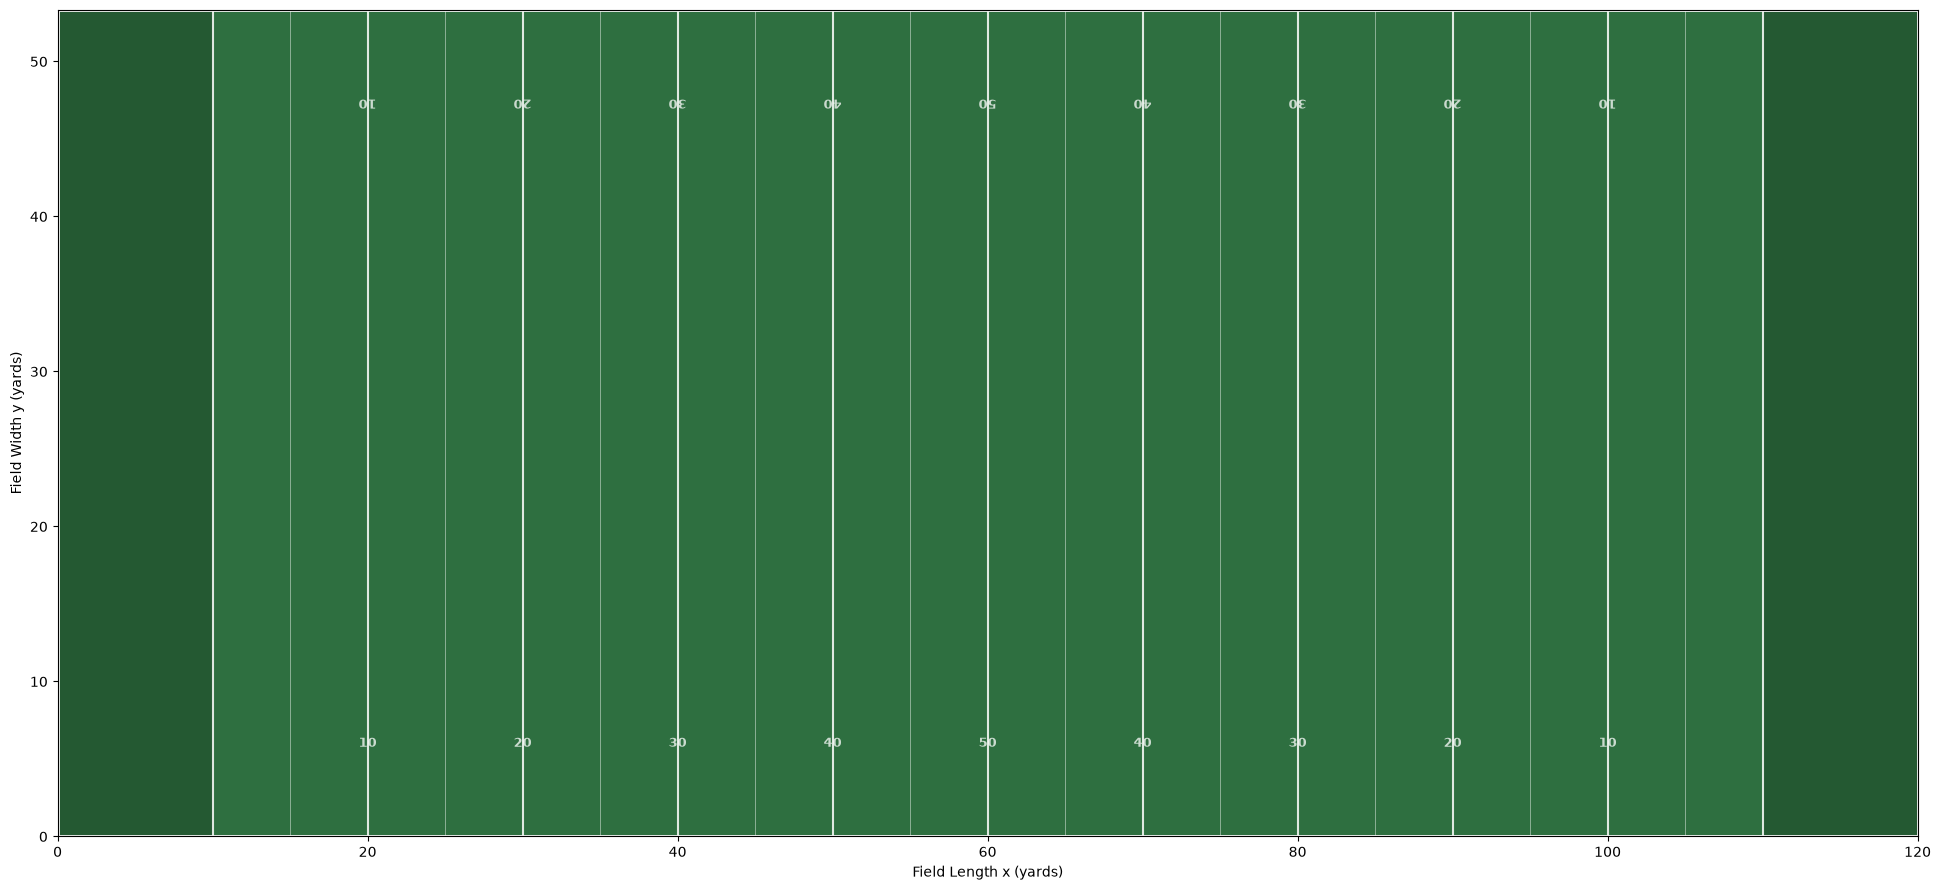

In [ ]:
fig,ax = plt.subplots(figsize=(24,11))
draw_nfl_field(ax)

In [ ]:
# shuttle_samples_ = combine_df[combine_df["drill_name"] == "THREE_CONE_DRILL"].drop(columns=["draft_year", "drill_type", "entity_type"]).groupby(["event_id", "nfl_id", "attempt"], sort=False)
three_cone_samples_ = pd.read_sql("SELECT * FROM df_combine_tracking WHERE drill_name == 'THREE_CONE_DRILL' AND entity_type != 'BALL' GROUP BY event_id, nfl_id, attempt", con)
# three_cone_samples = samples[samples["drill_name"] == "THREE_CONE_DRILL"]
# shuttle_samples = iter(shuttle_samples_)
# n, df_ = next(shuttle_samples)
# plot_combine_drill(df_)
# shuttle_samples_.head()

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir
0,2024,20240229100000_1709243283585_000,57169,PLAYER,2024-02-29 21:47:29.700000,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.133333,52.233333,0.576667,2.431033,0.004581,98.317649
1,2024,20240229100000_1709243297348_000,57434,PLAYER,2024-02-29 21:47:51.400000,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.866667,51.800000,1.380000,3.407498,0.010062,107.560272
2,2024,20240229100000_1709243398354_000,57160,PLAYER,2024-02-29 21:49:30.600000,THREE_CONE_DRILL,THREE_CONE_DRILL,2,95.300000,52.866667,0.570000,2.273372,0.004581,124.060909
3,2024,20240229100000_1709243403153_000,57160,PLAYER,2024-02-29 21:49:33.900000,THREE_CONE_DRILL,THREE_CONE_DRILL,3,96.666667,52.333333,1.896667,0.000000,0.000000,112.828775
4,2024,20240229100000_1709243457329_000,57216,PLAYER,2024-02-29 21:50:30,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.033333,52.233333,0.816667,2.147329,0.004444,106.363137


In [ ]:
# shuttle_samples_ = combine_df[combine_df["drill_name"] == "SHORT_SHUTTLE"].drop(columns=["draft_year", "drill_type", "entity_type"]).groupby(["event_id", "nfl_id", "attempt"], sort=False)
shuttle_samples_ = pd.read_sql("SELECT * FROM df_combine_tracking WHERE drill_name == 'SHORT_SHUTTLE' AND entity_type != 'BALL' GROUP BY event_id, nfl_id, attempt", con)

# three_cone_samples = samples[samples["drill_name"] == "THREE_CONE_DRILL"]
# shuttle_samples = iter(shuttle_samples_)
# n, df_ = next(shuttle_samples)
# plot_combine_drill(df_)

ValueError: too many values to unpack (expected 2)

In [ ]:
df = df_.drop(columns=["event_id", "nfl_id", "drill_name", "attempt"]).copy()
df["frame"] = range(1,len(df)+1)
# pd.pivot(df, columns=["frame"], values=["x", "y", "s", "a", "dis", "dir"])
df.set_index("frame").T

frame,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
time,2025-03-02 21:13:20.700000,2025-03-02 21:13:20.800000,2025-03-02 21:13:20.900000,2025-03-02 21:13:21,2025-03-02 21:13:21.100000,2025-03-02 21:13:21.200000,2025-03-02 21:13:21.300000,2025-03-02 21:13:21.400000,2025-03-02 21:13:21.500000,2025-03-02 21:13:21.600000,...,2025-03-02 21:13:22.700000,2025-03-02 21:13:22.800000,2025-03-02 21:13:22.900000,2025-03-02 21:13:23,2025-03-02 21:13:23.100000,2025-03-02 21:13:23.200000,2025-03-02 21:13:23.300000,2025-03-02 21:13:23.400000,2025-03-02 21:13:23.500000,2025-03-02 21:13:23.600000
x,94.888072,94.948812,95.043864,95.18335,95.364126,95.591685,95.864207,96.133596,96.424255,96.729014,...,98.548147,98.395874,98.176534,97.899719,97.564768,97.192291,96.772664,96.328206,95.779327,95.213725
y,17.176617,17.184373,17.179652,17.145344,17.124914,17.146859,17.178416,17.187805,17.19605,17.201986,...,17.041892,17.000521,16.954678,16.908496,16.859717,16.813539,16.767852,16.72442,16.674844,16.633844
s,0.493748,0.720093,1.081096,1.452918,1.815643,2.160978,2.458603,2.691614,2.858644,2.993467,...,1.217935,1.820358,2.418338,2.972885,3.495,3.91754,4.308056,4.599398,4.915705,5.084277
a,2.665657,3.547709,3.599323,3.526631,3.335859,2.918116,2.250283,1.628742,0.895976,0.286563,...,6.122952,5.861814,5.483143,5.001384,4.504923,3.949977,3.368693,2.659183,1.700486,0.68276
dis,0.002961,0.00369,0.009035,0.019492,0.032683,0.051786,0.074275,0.07257,0.084483,0.092878,...,0.00874,0.02325,0.048156,0.076656,0.112217,0.138756,0.176099,0.197552,0.301278,0.319911
dir,71.876246,82.393165,88.50371,91.934021,91.862578,90.49896,89.120115,88.712496,88.440122,88.476248,...,252.512131,257.347622,259.801662,261.413007,262.498652,263.384126,264.106378,264.714854,265.240666,265.813754


In [14]:
# shuttle_samples_ = combine_df[combine_df["drill_name"] == "FORTY_YARD_DASH"].drop(columns=["draft_year", "drill_type", "entity_type"]).groupby(["event_id", "nfl_id", "attempt"], sort=False)
forty_samples_ = pd.read_sql("SELECT * FROM df_combine_tracking WHERE drill_name == 'FORTY_YARD_DASH' AND entity_type != 'BALL' GROUP BY event_id, nfl_id, attempt", con)

# three_cone_samples = samples[samples["drill_name"] == "THREE_CONE_DRILL"]
# shuttle_samples = iter(shuttle_samples_)
# n, df_ = next(shuttle_samples)
# plot_combine_drill(df_)

In [ ]:
combine_df["drill_name"].unique()

<StringArray>
[              'OL_PULL_DRILL_FOLD_BLOCK_RIGHT',
           'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT',
                'OL_PULL_DRILL_LONG_PULL_RIGHT',
                               'PASS_RUSH_DROP',
                                 'SCREEN_DRILL',
                        'PASS_PRO-MIRROR_DRILL',
       'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE',
                              'FORTY_YARD_DASH',
                             'THREE_CONE_DRILL',
                                'SHORT_SHUTTLE',
                           'RUN_THE_HOOP_DRILL',
                     'SHORT_ZONE_BREAK_FORWARD',
                  'SHORT_ZONE_BREAK_FLAT_WHEEL',
                      'SHORT_ZONE_BREAK_INSIDE',
                              'PASS_RUSH_DRILL',
                           'BODY_CONTROL_DRILL',
                       'FOUR_BAG_AGILITY_DRILL',
  'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION',
                         'BACK_PEDAL_AND_REACT',
                           'RUN_AND_CLUB_DRILL',
      

In [ ]:
combine_df["drill_type"].unique()

<StringArray>
[ 'SKILL_DRILLS_OL',  'FORTY_YARD_DASH', 'THREE_CONE_DRILL',
    'SHORT_SHUTTLE',  'SKILL_DRILLS_DL',  'SKILL_DRILLS_DB',
  'SKILL_DRILLS_TE',  'SKILL_DRILLS_WR',  'SKILL_DRILLS_LB']
Length: 9, dtype: str

In [ ]:
combine_df[combine_df["drill_type"] == "SKILL_DRILLS_WR"]["drill_name"].unique()

<StringArray>
['POST_CORNER_ROUTE_RIGHT',          'GAUNTLET_DRILL',
    'OVER_SHOULDER_ADJUST',          'GO_ROUTE_RIGHT',
       'CIRCUS_ROUTE_LEFT',        'SLANT_ROUTE_LEFT',
    'SPEED_OUT_ROUTE_LEFT',        'CURL_ROUTE_RIGHT',
       'DAGGER_ROUTE_LEFT',  'SLOT_STRIKE_ROUTE_LEFT',
    'COMEBACK_ROUTE_RIGHT',   'SLOT_SAIL_ROUTE_RIGHT',
     'RED_ZONE_FADE_RIGHT',          'SPEED_OUT_LEFT',
  'POST_CORNER_ROUTE_LEFT']
Length: 15, dtype: str

In [ ]:
def isolate_shuttle_phases(
    attempt_df: pd.DataFrame,
    acc_threshold: float = 1.5,    # yds/s^2 for acceleration bouts
    dec_threshold: float = -1.5,   # yds/s^2 (negative) for deceleration bouts
    min_frames: int = 3,           # 3 frames = 0.3s Minimum Effort Duration at 10 Hz
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Isolates acceleration and deceleration bouts for a single player drill attempt.
    Assumes 10 Hz tracking with columns: ['time', 'x', 'y', 's', 'a', 'dis', 'dir'].
    """
    attempt_df["time"] = pd.to_datetime(attempt_df["time"], format='ISO8601')
    df = attempt_df.sort_values("time").reset_index(drop=True).copy()
    dt = df["time"].diff().dt.total_seconds().fillna(0.1)

    # 1. Light rolling smoothing on speed to curb 10 Hz jitter before differencing
    df["s_smooth"] = df["s"].rolling(window=5, center=True, min_periods=1).mean()

    # 2. Signed longitudinal acceleration along the path (ds / dt)
    # Negative values indicate deceleration (braking); positive indicates speeding up.
    df["a_long"] = (df["s_smooth"].diff() / dt.replace(0, np.nan)).fillna(0.0)

    # Optional: velocity-vector dot product acceleration (captures directional + speed change)
    vx = df["x"].diff() / dt.replace(0, np.nan)
    vy = df["y"].diff() / dt.replace(0, np.nan)
    ax = vx.diff() / dt.replace(0, np.nan)
    ay = vy.diff() / dt.replace(0, np.nan)
    speed_vec = np.hypot(vx, vy)
    df["a_vec_long"] = np.where(
        speed_vec > 0.5,
        (vx * ax + vy * ay) / speed_vec,
        df["a_long"],
    )

    # 3. Classify each frame into a phase
    conditions = [
        df["a_long"] >= acc_threshold,
        df["a_long"] <= dec_threshold,
    ]
    df["phase"] = np.select(conditions, ["accel", "decel"], default="steady_or_transition")

    # 4. Assign contiguous bout IDs whenever phase or non-consecutive gap changes
    new_bout = (df["phase"] != df["phase"].shift()) | (dt > 0.15)
    df["bout_id"] = new_bout.cumsum()

    # 5. Aggregate each bout and enforce Minimum Effort Duration (MED)
    bouts = (
        df[df["phase"].isin(["accel", "decel"])]
        .groupby(["bout_id", "phase"], as_index=False)
        .agg(
            start_time=("time", "first"),
            end_time=("time", "last"),
            n_frames=("time", "count"),
            start_x=("x", "first"),
            end_x=("x", "last"),
            start_y=("y", "first"),
            end_y=("y", "last"),
            v_start=("s_smooth", "first"),
            v_end=("s_smooth", "last"),
            v_peak=("s_smooth", "max"),
            v_min=("s_smooth", "min"),
            a_mean=("a_long", "mean"),
            a_peak_mag=("a_long", lambda s: s.abs().max()),
            dist_yds=("dis", "sum"),
        )
    )
    bouts["duration_s"] = (bouts["end_time"] - bouts["start_time"]).dt.total_seconds() + 0.1
    bouts["delta_v"] = bouts["v_end"] - bouts["v_start"]
    bouts["braking_dist_per_yds_lost"] = np.where(
        (bouts["phase"] == "decel") & (bouts["delta_v"] < -0.25),
        bouts["dist_yds"] / bouts["delta_v"].abs(),
        np.nan,
    )

    bouts = bouts[bouts["n_frames"] >= min_frames].reset_index(drop=True)
    return df, bouts

In [ ]:
res = isolate_shuttle_phases(pd.read_sql("SELECT * FROM df_combine_tracking WHERE drill_name == 'SHORT_SHUTTLE' AND entity_type != 'BALL' GROUP BY event_id, nfl_id, attempt", con))
# res[0]

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,s_smooth,a_long,a_vec_long,phase,bout_id
0,2023,64065c26e3d8e72dcd19966c-2023,55877,PLAYER,2023-03-03 00:05:55.500,SHORT_SHUTTLE,SHORT_SHUTTLE,1,95.133333,15.800000,0.750000,2.835207,0.004581,112.796521,0.658889,0.000000,0.000000,steady_or_transition,1
1,2023,64065c26e3d8e72dcd19966e-2023,55877,PLAYER,2023-03-03 00:06:16.900,SHORT_SHUTTLE,SHORT_SHUTTLE,2,95.000000,15.966667,0.543333,2.840286,0.004444,91.054405,0.665833,0.000325,0.000325,steady_or_transition,2
2,2023,64065c26e3d8e72dcd199673-2023,55877,PLAYER,2023-03-03 00:08:27.900,SHORT_SHUTTLE,SHORT_SHUTTLE,3,95.233333,16.833333,0.683333,2.213117,0.004444,108.523505,0.636000,-0.000228,-0.000228,steady_or_transition,3
3,2023,64065c26e3d8e72dcd199680-2023,56571,PLAYER,2023-03-03 00:10:17.700,SHORT_SHUTTLE,SHORT_SHUTTLE,1,95.133333,13.233333,0.686667,2.140991,0.004444,102.347588,0.621333,-0.000134,-0.000134,steady_or_transition,4
4,2023,64065c26e3d8e72dcd19968e-2023,55877,PLAYER,2023-03-03 00:12:14.400,SHORT_SHUTTLE,SHORT_SHUTTLE,5,94.900000,17.433333,0.516667,2.341913,0.001571,148.150949,0.605333,-0.000137,-0.000137,steady_or_transition,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
218,2025,20250302101000_1740950007481_000,58261,PLAYER,2025-03-02 21:13:20.700,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.888072,17.176617,0.493748,2.665657,0.002961,71.876246,0.634713,-0.002809,-0.002809,steady_or_transition,219
219,2025,20250302101000_1740950033469_000,58455,PLAYER,2025-03-02 21:13:46.900,SHORT_SHUTTLE,SHORT_SHUTTLE,1,94.956685,17.005826,0.645142,2.323277,0.002806,101.516601,0.645352,0.000406,0.000406,steady_or_transition,220
220,2025,20250302101000_1740950071992_000,58303,PLAYER,2025-03-02 21:14:22.100,SHORT_SHUTTLE,SHORT_SHUTTLE,1,94.799184,16.482146,0.015142,0.086067,0.000514,47.726452,0.525944,-0.003392,-0.003392,steady_or_transition,221
221,2025,20250302101000_1740950115723_000,58898,PLAYER,2025-03-02 21:15:08.600,SHORT_SHUTTLE,SHORT_SHUTTLE,1,95.141439,15.689234,0.713175,2.446056,0.004708,103.618818,0.533994,0.000173,0.000173,steady_or_transition,222


In [ ]:
# sample = res[0].copy()
res[1]

,bout_id,phase,start_time,end_time,n_frames,start_x,end_x,start_y,end_y,v_start,v_end,v_peak,v_min,a_mean,a_peak_mag,dist_yds,duration_s,delta_v,braking_dist_per_yds_lost
0,2,accel,2025-03-02 21:13:20.800,2025-03-02 21:13:21.500,8,94.948812,96.424255,17.184373,17.196050,0.936964,2.803242,2.803242,0.936964,2.547828,3.477020,0.348013,0.8,1.866278,NaN
1,4,decel,2025-03-02 21:13:22.000,2025-03-02 21:13:22.400,5,97.923248,98.641459,17.207013,17.130170,2.517490,1.018856,2.517490,1.018856,-3.441188,4.531926,0.220919,0.5,-1.498635,0.147413
2,6,accel,2025-03-02 21:13:22.700,2025-03-02 21:13:23.500,9,98.548147,95.779327,17.041892,16.674844,1.279959,4.726859,4.726859,1.279959,4.180655,5.768217,1.082704,0.9,3.446900,NaN


In [38]:
# combine_w_pos_df = pd.merge(combine_df, combine_results_df[["nfl_id", "combine_position"]], on="nfl_id")
# shuttle_df = combine_w_pos_df[(combine_w_pos_df["drill_name"] == "SHORT_SHUTTLE") & (combine_w_pos_df["combine_position"].str.contains("wr|te", case=False))]
pos_query = """
SELECT df_combine_tracking.*, df_combine_results.combine_position FROM df_combine_tracking JOIN df_combine_results ON df_combine_tracking.nfl_id == df_combine_results.nfl_id WHERE drill_name == 'SHORT_SHUTTLE' AND df_combine_results.combine_position IN ('WR', 'TE')
"""
shuttle_df = pd.read_sql(pos_query, con)
shuttle_df

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,combine_position
0,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.500000,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.780548,18.338857,0.063562,0.277279,0.000382,139.074413,TE
1,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.600000,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.636220,18.345923,0.075792,0.509425,0.020831,207.993864,TE
2,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.700000,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.621358,18.343697,0.109470,0.713377,0.000221,180.660336,TE
3,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.800000,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.509857,18.300120,0.201982,1.010799,0.012577,201.466589,TE
4,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.900000,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.490692,18.256561,0.259172,1.289433,0.001933,177.326825,TE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3887,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58,SHORT_SHUTTLE,SHORT_SHUTTLE,1,93.366667,11.066667,4.690000,5.203679,0.187830,98.176197,TE
3888,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.100000,SHORT_SHUTTLE,SHORT_SHUTTLE,1,93.866667,11.000000,5.200000,4.345629,0.250040,97.330050,TE
3889,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.200000,SHORT_SHUTTLE,SHORT_SHUTTLE,1,94.400000,10.933333,5.496667,2.924308,0.284479,96.021736,TE
3890,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.300000,SHORT_SHUTTLE,SHORT_SHUTTLE,1,94.966667,10.900000,5.756667,2.285962,0.321113,95.083280,TE


In [35]:
def run_shuttle_phases_across_attempts(
    shuttle_df: pd.DataFrame,
    acc_threshold: float = 1.5,
    dec_threshold: float = -1.5,
    min_frames: int = 3,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Applies `isolate_shuttle_phases()` to each shuttle attempt while retaining
    `nfl_id`, `event_id`, and `attempt` on every output row.
    """
    # Filter to PLAYER rows just in case BALL rows are present
    if "entity_type" in shuttle_df.columns:
        shuttle_df = shuttle_df[shuttle_df["entity_type"] == "PLAYER"].copy()

    frame_chunks = []
    bout_chunks = []

    group_cols = ["nfl_id", "event_id", "attempt"]
    for (nfl_id, event_id, attempt), attempt_df in shuttle_df.groupby(group_cols, dropna=False, sort=False):
        # Skip tiny/corrupted attempts that don't have enough frames to smooth
        if len(attempt_df) < 5:
            continue

        frames_out, bouts_out = isolate_shuttle_phases(
            attempt_df,
            acc_threshold=acc_threshold,
            dec_threshold=dec_threshold,
            min_frames=min_frames,
        )

        # Attach identifiers explicitly so nothing is lost or misaligned
        frames_out["nfl_id"] = nfl_id
        frames_out["event_id"] = event_id
        frames_out["attempt"] = attempt
        frame_chunks.append(frames_out)

        if not bouts_out.empty:
            bouts_out["nfl_id"] = nfl_id
            bouts_out["event_id"] = event_id
            bouts_out["attempt"] = attempt
            bout_chunks.append(bouts_out)

    all_frames = pd.concat(frame_chunks, ignore_index=True) if frame_chunks else pd.DataFrame()
    all_bouts = pd.concat(bout_chunks, ignore_index=True) if bout_chunks else pd.DataFrame()

    # Bring key identifiers to the front for readability
    id_cols = [c for c in ["nfl_id", "event_id", "attempt"] if c in all_bouts.columns]
    if not all_bouts.empty:
        other_cols = [c for c in all_bouts.columns if c not in id_cols]
        all_bouts = all_bouts[id_cols + other_cols]

    return all_frames, all_bouts

In [39]:
res = run_shuttle_phases_across_attempts(shuttle_df)
res[0]

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,combine_position,s_smooth,a_long,a_vec_long,phase,bout_id
0,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.500,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.780548,18.338857,0.063562,0.277279,0.000382,139.074413,TE,0.082941,0.000000,0.000000,steady_or_transition,1
1,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.600,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.636220,18.345923,0.075792,0.509425,0.020831,207.993864,TE,0.112701,0.297602,NaN,steady_or_transition,1
2,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.700,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.621358,18.343697,0.109470,0.713377,0.000221,180.660336,TE,0.141995,0.292941,0.292941,steady_or_transition,1
3,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.800,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.509857,18.300120,0.201982,1.010799,0.012577,201.466589,TE,0.194458,0.524627,10.506090,steady_or_transition,1
4,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.900,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.490692,18.256561,0.259172,1.289433,0.001933,177.326825,TE,0.268436,0.739781,0.739781,steady_or_transition,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3887,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.000,SHORT_SHUTTLE,SHORT_SHUTTLE,1,93.366667,11.066667,4.690000,5.203679,0.187830,98.176197,TE,4.610000,5.293333,3.294573,accel,10
3888,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.100,SHORT_SHUTTLE,SHORT_SHUTTLE,1,93.866667,11.000000,5.200000,4.345629,0.250040,97.330050,TE,5.056667,4.466667,6.608185,accel,10
3889,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.200,SHORT_SHUTTLE,SHORT_SHUTTLE,1,94.400000,10.933333,5.496667,2.924308,0.284479,96.021736,TE,5.414667,3.580000,3.307593,accel,10
3890,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.300,SHORT_SHUTTLE,SHORT_SHUTTLE,1,94.966667,10.900000,5.756667,2.285962,0.321113,95.083280,TE,5.595833,1.811667,3.131842,accel,10


In [40]:
all_bouts = res[1].sort_values(["nfl_id", "event_id", "attempt", "start_time"]).copy()
all_bouts["bout_num_in_phase"] = all_bouts.groupby(["event_id", "phase"]).cumcount() + 1

In [41]:
with pd.option_context('display.max_columns', None):
    display(all_bouts.sort_values(by=['event_id', 'attempt', 'bout_id']).head(10))

,nfl_id,event_id,attempt,bout_id,phase,start_time,end_time,n_frames,start_x,end_x,start_y,end_y,v_start,v_end,v_peak,v_min,a_mean,a_peak_mag,dist_yds,duration_s,delta_v,braking_dist_per_yds_lost,bout_num_in_phase
216,57244,20240301100500_1709344335579_000,2,2,accel,2024-03-02 01:52:08.100,2024-03-02 01:52:08.700,7,95.300000,94.100000,16.466667,15.900000,1.195333,2.494667,2.494667,1.195333,2.096190,2.400000,0.298386,0.7,1.299333,NaN,1
217,57244,20240301100500_1709344335579_000,2,4,decel,2024-03-02 01:52:09.300,2024-03-02 01:52:09.700,5,92.433333,91.766667,15.866667,15.966667,2.360667,0.974000,2.360667,0.974000,-3.146667,4.446667,0.193430,0.5,-1.386667,0.139493,1
218,57244,20240301100500_1709344335579_000,2,6,accel,2024-03-02 01:52:09.900,2024-03-02 01:52:10.700,9,91.833333,94.633333,16.000000,15.900000,1.078000,4.861333,4.861333,1.078000,4.396296,6.266667,1.133397,0.9,3.783333,NaN,2
219,57244,20240301100500_1709344335579_000,2,8,decel,2024-03-02 01:52:11.100,2024-03-02 01:52:11.900,9,96.733333,98.966667,16.066667,16.633333,4.735333,1.137333,4.735333,1.137333,-4.196296,6.486667,1.036341,0.9,-3.598000,0.288033,2
220,57244,20240301100500_1709344335579_000,2,10,accel,2024-03-02 01:52:12.100,2024-03-02 01:52:12.900,9,98.833333,95.800000,16.700000,16.666667,1.490667,5.411333,5.411333,1.490667,4.709630,6.460000,1.282320,0.9,3.920667,NaN,3
221,57244,20240301100500_1709344437782_000,3,2,accel,2024-03-02 01:53:50.200,2024-03-02 01:53:51.000,9,96.033333,94.600000,16.733333,16.033333,0.552667,2.860000,2.860000,0.552667,2.782963,3.586667,0.359882,0.9,2.307333,NaN,1
222,57244,20240301100500_1709344437782_000,3,4,decel,2024-03-02 01:53:51.600,2024-03-02 01:53:52.100,6,92.766667,91.900000,15.800000,15.933333,2.700667,0.955333,2.700667,0.955333,-3.228889,4.513333,0.261258,0.6,-1.745333,0.149690,1
223,57244,20240301100500_1709344437782_000,3,6,accel,2024-03-02 01:53:52.300,2024-03-02 01:53:53.100,9,92.033333,95.033333,15.933333,15.800000,1.216000,5.009333,5.009333,1.216000,4.497037,6.566667,1.303501,0.9,3.793333,NaN,2
224,57244,20240301100500_1709344437782_000,3,8,decel,2024-03-02 01:53:53.400,2024-03-02 01:53:54.200,9,96.600000,98.866667,15.933333,16.733333,4.842000,1.297333,4.842000,1.297333,-4.124444,6.486667,1.108964,0.9,-3.544667,0.312854,2
225,57244,20240301100500_1709344437782_000,3,10,accel,2024-03-02 01:53:54.400,2024-03-02 01:53:55.300,10,98.700000,94.800000,16.800000,16.400000,1.696667,5.828889,5.828889,1.696667,4.482889,6.786667,1.840249,1.0,4.132222,NaN,3


In [ ]:
dec_summary = (
    all_bouts[all_bouts["phase"] == "decel"]
    .groupby(["nfl_id", "event_id", "attempt"], as_index=False)
    .agg(
        n_dec_bouts=("bout_id", "count"),
        max_braking_mag=("a_peak_mag", "max"),
        mean_braking_mag=("a_peak_mag", "mean"),
        min_braking_dist_per_yds=("braking_dist_per_yds_lost", "min"),
    )
)

acc_summary = (
    all_bouts[all_bouts["phase"] == "accel"]
    .groupby(["nfl_id", "event_id", "attempt"], as_index=False)
    .agg(
        n_acc_bouts=("bout_id", "count"),
        max_accel_mean=("a_mean", "max"),
        max_speed_in_bout=("v_peak", "max"),
    )
)

attempt_metrics = pd.merge(dec_summary, acc_summary, on=["nfl_id", "event_id", "attempt"], how="outer")

In [42]:
def pivot_drill_phases_to_player(
    phase_df: pd.DataFrame,
    metric_cols: list[str],
    player_agg: str = "max",
) -> pd.DataFrame:
    """
    Aggregates across multiple attempts per (nfl_id, phase), then pivots phases
    into columns so each player (`nfl_id`) has one row with phase-specific features.
    """
    # 1. Collapse multiple attempts of the same phase per player
    per_player_phase = (
        phase_df.groupby(["nfl_id", "phase"], as_index=False)[metric_cols]
        .agg(player_agg)
    )

    # 2. Pivot so columns look like '<metric>__<phase>'
    pivoted = per_player_phase.pivot(index="nfl_id", columns="phase", values=metric_cols)
    pivoted.columns = [f"{metric}__{phase}" for metric, phase in pivoted.columns]
    return pivoted.reset_index()

In [47]:
pivoted_shuttle_df = pivot_drill_phases_to_player(res[1], metric_cols=["v_start", "v_end", "v_peak", "v_min", "a_mean", "a_peak_mag", "dist_yds", "duration_s", "braking_dist_per_yds_lost"])

In [ ]:
def top_cross_dataset_correlations(
    route_df: pd.DataFrame,
    combine_df: pd.DataFrame,
    method: str = "pearson",  # "pearson" or "spearman"
    min_n: int = 15,
    top_k: int = 20,
) -> pd.DataFrame:
    """
    Computes pairwise correlations between numeric columns in `route_df`
    and numeric columns in `combine_df` (joined on `nfl_id`), ranked by |r| or |rho|.
    """
    merged = pd.merge(route_df, combine_df, on="nfl_id", how="inner")

    route_num_cols = [
        c for c in route_df.select_dtypes(include=[np.number]).columns if c != "nfl_id"
    ]
    comb_num_cols = [
        c for c in combine_df.select_dtypes(include=[np.number]).columns if c != "nfl_id"
    ]

    records = []
    for r_col in route_num_cols:
        for c_col in comb_num_cols:
            pair = merged[[r_col, c_col]].dropna()
            n_obs = len(pair)
            if n_obs < min_n:
                continue
            if pair[r_col].nunique() < 2 or pair[c_col].nunique() < 2:
                continue

            corr_val = pair[r_col].corr(pair[c_col], method=method)
            if pd.notna(corr_val):
                records.append({
                    "route_metric": r_col,
                    "combine_metric": c_col,
                    "n_players": n_obs,
                    "corr": float(corr_val),
                    "abs_corr": abs(float(corr_val)),
                })

    if not records:
        return pd.DataFrame()

    out = (
        pd.DataFrame(records)
        .sort_values("abs_corr", ascending=False)
        .drop(columns=["abs_corr"])
        .reset_index(drop=True)
    )
    return out.head(top_k)

In [ ]:
attempt_metrics

,nfl_id,event_id,attempt,n_dec_bouts,max_braking_mag,mean_braking_mag,min_braking_dist_per_yds,n_acc_bouts,max_accel_mean,max_speed_in_bout
0,55915,6414e684e3d8e72dcdcb5029-2023,1,2.0,8.126667,6.690000,0.177381,3,5.028148,6.083333
1,55915,6414e684e3d8e72dcdcb5033-2023,2,2.0,7.873333,6.293333,0.169658,3,5.281852,6.021667
2,55943,6414e6d3e3d8e72dcdcd0470-2023,1,2.0,7.166667,5.853333,0.139359,3,5.452500,5.768667
3,55958,6414e6d3e3d8e72dcdcd0444-2023,1,2.0,6.166667,6.030000,0.151081,3,4.592593,5.180667
4,55958,6414e6d3e3d8e72dcdcd044a-2023,2,1.0,4.893333,4.893333,0.143663,2,4.712667,5.636667
...,...,...,...,...,...,...,...,...,...,...
68,58460,20250228100500_1740793791319_000,1,2.0,7.423815,6.200567,0.152126,3,5.117447,5.968624
69,58734,20250301100700_1740868168797_000,1,2.0,6.497096,5.777304,0.171159,3,4.771024,6.060628
70,58737,20250228100500_1740793645339_000,1,2.0,7.949584,6.342359,0.155306,3,5.373340,5.533120
71,58901,20250301100700_1740868142177_000,2,2.0,7.441555,5.747903,0.122652,3,5.394849,5.990632


In [ ]:
def extract_40yd_kinematics_robust(
    forty_df: pd.DataFrame,
    combine_results_df: pd.DataFrame | None = None,
    acc_threshold: float = 1.5,
    start_speed_threshold: float = 0.5,
) -> pd.DataFrame:
    if "entity_type" in forty_df.columns:
        forty_df = forty_df[forty_df["entity_type"] == "PLAYER"].copy()
    forty_df["time"] = pd.to_datetime(forty_df["time"], format='ISO8601')

    rows = []
    group_cols = ["nfl_id", "event_id", "attempt"]

    for (nfl_id, event_id, attempt), g in forty_df.groupby(group_cols, dropna=False, sort=False):
        g = g.sort_values("time").reset_index(drop=True)
        if len(g) < 3:
            continue

        if np.issubdtype(g["time"].dtype, np.datetime64) or np.issubdtype(g["time"].dtype, np.timedelta64):
            t_rel = (g["time"] - g["time"].iloc[0]).dt.total_seconds().to_numpy()
        else:
            t_rel = (g["time"] - g["time"].iloc[0]).to_numpy(dtype=float)

        attempt_duration_s = float(t_rel[-1] - t_rel[0]) if len(t_rel) > 1 else np.nan
        s_smooth = g["s"].rolling(window=5, center=True, min_periods=1).mean().to_numpy()
        a_long = (
            np.gradient(s_smooth, t_rel)
            if len(t_rel) >= 2 and np.all(np.diff(t_rel) > 0)
            else np.zeros_like(s_smooth)
        )

        dis_arr = g["dis"].fillna(0.0).to_numpy()
        total_attempt_dist_yds = float(np.sum(dis_arr))

        active_idx = np.flatnonzero(s_smooth >= start_speed_threshold)
        start_idx = int(active_idx[0]) if len(active_idx) > 0 else 0
        t_start = t_rel[start_idx]

        cum_dist_from_start = np.cumsum(dis_arr) - np.cumsum(dis_arr)[start_idx]
        crossed_40 = np.flatnonzero(cum_dist_from_start >= 40.0)

        if len(crossed_40) > 0:
            end_idx = int(crossed_40[0])
            if end_idx > start_idx and cum_dist_from_start[end_idx] > cum_dist_from_start[end_idx - 1]:
                frac = (40.0 - cum_dist_from_start[end_idx - 1]) / (
                    cum_dist_from_start[end_idx] - cum_dist_from_start[end_idx - 1]
                )
                t_40 = t_rel[end_idx - 1] + frac * (t_rel[end_idx] - t_rel[end_idx - 1])
            else:
                t_40 = t_rel[end_idx]
            tracking_40yd_time_s = float(t_40 - t_start)
            time_method = "interp_40yd"
            sprint_mask = (np.arange(len(g)) >= start_idx) & (np.arange(len(g)) <= end_idx)
        else:
            # Fallback to full attempt window when 40-yd crossing isn't reached in tracking
            tracking_40yd_time_s = attempt_duration_s
            time_method = "window_fallback"
            sprint_mask = np.arange(len(g)) >= 0

        s_sprint = s_smooth[sprint_mask]
        a_sprint = a_long[sprint_mask]
        t_sprint = t_rel[sprint_mask]

        if len(s_sprint) == 0:
            continue

        v_peak = float(np.max(s_sprint))
        if pd.isna(v_peak) or v_peak <= 0:
            continue

        reach_90_pos = np.flatnonzero(s_sprint >= 0.90 * v_peak)
        if len(reach_90_pos) > 0:
            p90 = int(reach_90_pos[0])
            t_to_90pct = float(t_sprint[p90] - t_sprint[0])
        else:
            t_to_90pct = np.nan

        accel_mask = a_sprint >= acc_threshold
        mean_accel_drive = float(np.mean(a_sprint[accel_mask])) if np.any(accel_mask) else np.nan
        peak_accel = float(np.max(a_sprint))
        top_speed_mask = s_sprint >= 0.95 * v_peak
        mean_top_speed = float(np.mean(s_sprint[top_speed_mask])) if np.any(top_speed_mask) else v_peak

        rows.append({
            "nfl_id": nfl_id,
            "event_id": event_id,
            "attempt": attempt,
            "tracking_40yd_time_s": tracking_40yd_time_s,
            "attempt_duration_s": attempt_duration_s,
            "total_attempt_dist_yds": total_attempt_dist_yds,
            "time_method": time_method,
            "v_peak_yds": v_peak,
            "v_peak_mph": v_peak * 2.04545,
            "mean_top_speed_yds": mean_top_speed,
            "peak_accel_yds2": peak_accel,
            "mean_accel_drive_yds2": mean_accel_drive,
            "t_to_90pct_vpeak_s": t_to_90pct,
        })

    out = pd.DataFrame(rows)
    if combine_results_df is not None and not out.empty:
        cols_to_keep = [c for c in ["nfl_id", "forty", "ten_yd_split"] if c in combine_results_df.columns]
        if "nfl_id" in cols_to_keep:
            bench = combine_results_df[cols_to_keep].drop_duplicates(subset=["nfl_id"])
            out = out.merge(bench, on="nfl_id", how="left").rename(columns={"forty": "official_forty_s"})
    return out

In [ ]:
def best_attempt_per_player(
    metrics_df: pd.DataFrame,
    metric_col: str,
    higher_is_better: bool = True,
) -> pd.DataFrame:
    """
    Returns one row per `nfl_id` corresponding to each player's best attempt
    on `metric_col` (preserving all other columns from that exact attempt).
    """
    valid = metrics_df.dropna(subset=[metric_col]).copy()
    if valid.empty:
        return pd.DataFrame(columns=metrics_df.columns)

    # Sort so the best attempt per player comes first
    valid = valid.sort_values(
        by=[metric_col, "attempt"],
        ascending=[not higher_is_better, True],
    )

    best_df = valid.drop_duplicates(subset=["nfl_id"], keep="first").reset_index(drop=True)
    return best_df

In [ ]:
forty_df = extract_40yd_kinematics_robust(combine_df[combine_df["drill_name"] == "FORTY_YARD_DASH"])
forty_df

,nfl_id,event_id,attempt,tracking_40yd_time_s,attempt_duration_s,total_attempt_dist_yds,time_method,v_peak_yds,v_peak_mph,mean_top_speed_yds,peak_accel_yds2,mean_accel_drive_yds2,t_to_90pct_vpeak_s
0,58896,20250302101000_1740946089384_000,1,5.8,5.8,33.023236,window_fallback,9.108454,18.630887,9.010662,4.212413,2.943364,2.8
1,58896,20250302101000_1740946604458_000,2,5.5,5.5,32.967082,window_fallback,9.239366,18.898661,9.075132,4.993053,3.247640,2.6
2,58261,20250302101000_1740946012561_000,1,6.0,6.0,33.140000,window_fallback,9.041241,18.493407,8.946827,4.260084,3.087830,2.9
3,58261,20250302101000_1740946523648_000,2,5.8,5.8,32.812886,window_fallback,9.136562,18.688381,9.015389,4.339912,3.108191,2.8
4,58454,20250302100900_1740939268259_000,1,5.7,5.7,33.807211,window_fallback,9.413043,19.253910,9.236641,4.223245,3.029490,2.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
788,56085,6414e6d3e3d8e72dcdcd0313-2023,2,5.0,5.0,37.738049,window_fallback,10.942000,22.381314,10.776987,5.453333,3.239537,2.9
789,56010,640669e0e3d8e72dcdb59e26-2023,2,5.0,5.0,37.659169,window_fallback,10.711667,21.910179,10.539599,5.673333,3.876905,2.7
790,56010,640669e0e3d8e72dcdb59df2-2023,1,4.9,4.9,37.160274,window_fallback,10.746667,21.981769,10.571559,5.420000,3.601970,2.7
791,56040,6414e6d3e3d8e72dcdcd02ed-2023,1,5.1,5.1,35.048934,window_fallback,9.901333,20.252682,9.811011,5.156667,3.299533,2.3


In [ ]:
single_forty_df = forty_df.drop_duplicates(subset=["nfl_id"]).set_index("nfl_id")
single_shuttle_df = attempt_metrics.drop_duplicates(subset=["nfl_id"]).set_index("nfl_id")
# shuttle_forty_df = single_shuttle_df.join(single_forty_df, on="nfl_id", how="inner", suffixes=("_forty", "_shuttle"))
shuttle_forty_df = attempt_metrics.join(single_forty_df, on="nfl_id", how="inner", suffixes=("_forty", "_shuttle"))
with pd.option_context("display.max_columns", None):
    display(shuttle_forty_df)

,nfl_id,event_id_forty,attempt_forty,n_dec_bouts,max_braking_mag,mean_braking_mag,min_braking_dist_per_yds,n_acc_bouts,max_accel_mean,max_speed_in_bout,event_id_shuttle,attempt_shuttle,tracking_40yd_time_s,attempt_duration_s,total_attempt_dist_yds,time_method,v_peak_yds,v_peak_mph,mean_top_speed_yds,peak_accel_yds2,mean_accel_drive_yds2,t_to_90pct_vpeak_s
0,55915,6414e684e3d8e72dcdcb5029-2023,1,2.0,8.126667,6.690000,0.177381,3,5.028148,6.083333,6414e684e3d8e72dcdcb4d5f-2023,2,4.9,4.9,38.350791,window_fallback,10.996667,22.493132,10.836288,5.393333,3.471467,2.6
1,55915,6414e684e3d8e72dcdcb5033-2023,2,2.0,7.873333,6.293333,0.169658,3,5.281852,6.021667,6414e684e3d8e72dcdcb4d5f-2023,2,4.9,4.9,38.350791,window_fallback,10.996667,22.493132,10.836288,5.393333,3.471467,2.6
2,55943,6414e6d3e3d8e72dcdcd0470-2023,1,2.0,7.166667,5.853333,0.139359,3,5.452500,5.768667,6414e6d3e3d8e72dcdcd02f3-2023,2,5.0,5.0,35.611833,window_fallback,10.346667,21.163589,10.204475,5.670000,3.893377,2.8
3,55958,6414e6d3e3d8e72dcdcd0444-2023,1,2.0,6.166667,6.030000,0.151081,3,4.592593,5.180667,6414e6d3e3d8e72dcdcd0305-2023,1,4.8,4.8,36.814543,window_fallback,10.776667,22.043133,10.630078,5.773333,3.671364,2.7
4,55958,6414e6d3e3d8e72dcdcd044a-2023,2,1.0,4.893333,4.893333,0.143663,2,4.712667,5.636667,6414e6d3e3d8e72dcdcd0305-2023,1,4.8,4.8,36.814543,window_fallback,10.776667,22.043133,10.630078,5.773333,3.671364,2.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,58449,20250301100800_1740877443105_000,1,2.0,7.013966,5.693462,0.163129,3,4.708981,5.966392,20250301100800_1740870539260_000,1,4.9,4.9,39.565580,window_fallback,11.412451,23.343599,11.266314,5.436278,3.741974,3.1
69,58734,20250301100700_1740868168797_000,1,2.0,6.497096,5.777304,0.171159,3,4.771024,6.060628,20250301100700_1740861476575_000,1,5.1,5.1,38.052981,window_fallback,10.948849,22.395323,10.764320,5.526657,3.680185,2.8
70,58737,20250228100500_1740793645339_000,1,2.0,7.949584,6.342359,0.155306,3,5.373340,5.533120,20250228100500_1740788889046_000,2,5.2,5.2,36.133127,window_fallback,10.292740,21.053285,10.149848,4.960979,3.397645,2.7
71,58901,20250301100700_1740868142177_000,2,2.0,7.441555,5.747903,0.122652,3,5.394849,5.990632,20250301100700_1740862677028_000,2,4.9,4.9,38.959934,window_fallback,11.094926,22.694117,10.938057,5.581927,3.715200,2.7


In [ ]:
shuttle_forty_df["shuttle_topspeed_pct"] = shuttle_forty_df["max_speed_in_bout"] / shuttle_forty_df["v_peak_yds"]

<Axes: xlabel='v_peak_yds', ylabel='shuttle_topspeed_pct'>

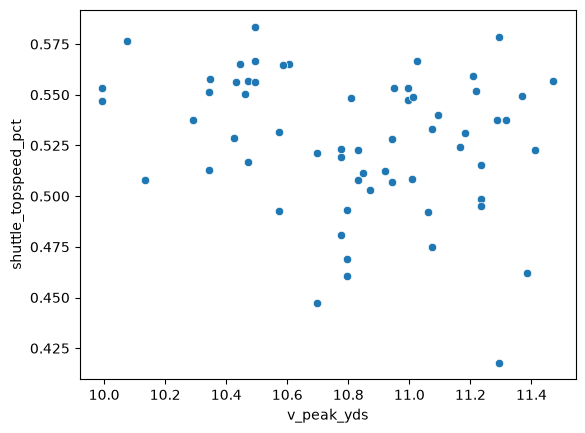

In [ ]:
sns.scatterplot(data=shuttle_forty_df[shuttle_forty_df["nfl_id"] != 58424], x="v_peak_yds", y="shuttle_topspeed_pct")

In [ ]:
display(players_df[players_df["nfl_id"] == 58424])
combine_results_df[combine_results_df["nfl_id"] == 58424]

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
448,58424,Thomas Fidone,2025,TE,2002-09-20,Nebraska,Big Ten Conference,7.0,3.0,219.0


,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
457,2025,58424,TE,77.0,243,10.625,34.0,82.625,1.57,4.7,35.5,126.0,7.01,4.29,NaN,75,67.0,72.0


In [ ]:
def parse_three_cone_attempt(
    attempt_df: pd.DataFrame,
    acc_threshold: float = 1.5,
    dec_threshold: float = -1.5,
    turn_rate_threshold_deg_s: float = 45.0,
    min_frames: int = 3,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Parses a single 10 Hz 3-cone tracking attempt into kinematic signals and
    candidate movement segments (bursts, breakdowns, turns/corners).
    Expected columns: ['time', 'x', 'y', 's', 'a', 'dis', 'dir'].
    """
    attempt_df["time"] = pd.to_datetime(attempt_df["time"], format='ISO8601')
    df = attempt_df.sort_values("time").reset_index(drop=True).copy()

    # Relative time in seconds
    if np.issubdtype(df["time"].dtype, np.datetime64) or np.issubdtype(df["time"].dtype, np.timedelta64):
        t_rel = (df["time"] - df["time"].iloc[0]).dt.total_seconds().to_numpy()
    else:
        t_rel = (df["time"] - df["time"].iloc[0]).to_numpy(dtype=float)

    dt = np.diff(t_rel, prepend=t_rel[0])
    dt = np.where(dt <= 0, 0.1, dt)
    df["t_rel"] = t_rel

    # 1. Smooth speed and compute signed longitudinal acceleration (ds / dt)
    df["s_smooth"] = df["s"].rolling(window=5, center=True, min_periods=1).mean()
    s_arr = df["s_smooth"].to_numpy()
    df["a_long"] = np.gradient(s_arr, t_rel) if len(t_rel) >= 2 and np.all(np.diff(t_rel) > 0) else 0.0

    # 2. Unwrap heading (`dir`) in radians to compute angular turn rate (deg/s)
    if "dir" in df.columns and df["dir"].notna().any():
        dir_rad_unwrapped = np.unwrap(np.deg2rad(df["dir"].interpolate(limit_direction="both").to_numpy()))
        turn_rate_rad_s = np.gradient(dir_rad_unwrapped, t_rel) if len(t_rel) >= 2 else np.zeros_like(dir_rad_unwrapped)
        df["turn_rate_deg_s"] = np.rad2deg(turn_rate_rad_s)
        df["abs_turn_rate_deg_s"] = np.abs(df["turn_rate_deg_s"])
        df["cum_abs_turn_deg"] = np.cumsum(np.abs(np.rad2deg(np.diff(dir_rad_unwrapped, prepend=dir_rad_unwrapped[0]))))
    else:
        df["turn_rate_deg_s"] = 0.0
        df["abs_turn_rate_deg_s"] = 0.0
        df["cum_abs_turn_deg"] = 0.0

    # 3. Classify frame-level movement regime:
    #    - 'turn_or_corner': significant directional change while moving
    #    - 'breakdown': strong deceleration
    #    - 'burst': strong acceleration
    #    - 'other': steady/transition
    is_turning = (df["abs_turn_rate_deg_s"] >= turn_rate_threshold_deg_s) & (df["s_smooth"] >= 1.0)
    is_decel = (~is_turning) & (df["a_long"] <= dec_threshold)
    is_accel = (~is_turning) & (df["a_long"] >= acc_threshold)

    df["regime"] = np.select(
        [is_turning, is_decel, is_accel],
        ["turn_or_corner", "breakdown", "burst"],
        default="other",
    )

    # 4. Group contiguous regimes into segments
    new_seg = (df["regime"] != df["regime"].shift()) | (dt > 0.15)
    df["seg_id"] = new_seg.cumsum()

    segs = (
        df[df["regime"] != "other"]
        .groupby(["seg_id", "regime"], as_index=False)
        .agg(
            t_start=("t_rel", "first"),
            t_end=("t_rel", "last"),
            n_frames=("t_rel", "count"),
            x_start=("x", "first"),
            x_end=("x", "last"),
            y_start=("y", "first"),
            y_end=("y", "last"),
            v_start=("s_smooth", "first"),
            v_end=("s_smooth", "last"),
            v_peak=("s_smooth", "max"),
            v_min=("s_smooth", "min"),
            a_long_mean=("a_long", "mean"),
            peak_decel_mag=("a_long", lambda s: float(np.abs(np.min(s))) if len(s) > 0 else np.nan),
            peak_accel_mag=("a_long", lambda s: float(np.max(s)) if len(s) > 0 else np.nan),
            peak_turn_rate_deg_s=("abs_turn_rate_deg_s", "max"),
            net_turn_deg=("turn_rate_deg_s", lambda s: float(np.sum(s) * 0.1)),
            dist_yds=("dis", "sum"),
        )
    )
    segs["delta_v"] = segs["v_end"] - segs["v_start"]
    segs = segs[segs["n_frames"] >= min_frames].reset_index(drop=True)
    segs["seq_order"] = np.arange(1, len(segs) + 1)

    return df, segs

In [ ]:
res = parse_three_cone_attempt(combine_w_pos_df[combine_w_pos_df["drill_name"] == "THREE_CONE_DRILL"])
event_segs = res[0][res[0]["event_id"] == "6407d3f0e3d8e72dcdb2faed-2023"]["seg_id"].to_list()
with pd.option_context("display.max_columns", None):
    display(res[1].loc[res[1]["seg_id"].isin(event_segs)])

,seg_id,regime,t_start,t_end,n_frames,x_start,x_end,y_start,y_end,v_start,v_end,v_peak,v_min,a_long_mean,peak_decel_mag,peak_accel_mag,peak_turn_rate_deg_s,net_turn_deg,dist_yds,delta_v,seq_order
0,2,burst,0.2,0.6,5,95.600000,96.433333,51.633333,51.766667,1.208667,2.273333,2.273333,1.208667,2.417167,1.750000,3.010000,8.169589,1.864049,0.201311,1.064667,1
1,4,breakdown,1.1,1.6,6,97.666667,98.400000,51.966667,52.100000,2.167333,0.724667,2.167333,0.724667,-2.593333,3.556667,-1.543333,669.289215,-74.701403,0.164652,-1.442667,2
2,6,burst,1.9,2.1,3,98.200000,97.900000,52.066667,52.000000,0.957333,1.576667,1.576667,0.957333,2.752222,2.336667,3.096667,55.215323,-6.854788,0.063425,0.619333,3
3,14,burst,3.3,3.8,6,96.833333,98.133333,51.566667,51.133333,1.544000,3.390000,3.390000,1.544000,3.568889,1.970000,4.600000,39.934001,5.876036,0.366618,1.846000,4
4,15,turn_or_corner,3.9,4.6,8,98.466667,100.000000,50.966667,48.900000,3.551333,3.782000,3.782000,3.551333,0.371250,0.130000,1.253333,73.400513,51.938115,0.938625,0.230667,5
5,17,breakdown,4.9,5.1,3,100.166667,100.200000,47.766667,47.133333,3.458667,2.778667,3.458667,2.778667,-3.352222,4.196667,-2.460000,23.966358,-1.096793,0.335566,-0.680000,6
6,18,turn_or_corner,5.2,7.2,21,100.233333,98.300000,46.866667,51.233333,2.320667,5.451333,5.451333,1.360000,1.415397,4.590000,4.076667,389.592664,-243.075030,2.246811,3.130667,7
7,20,breakdown,7.6,7.8,3,96.066667,94.866667,51.800000,51.900000,5.937333,3.941333,5.937333,3.941333,-8.109240,9.980000,-4.570000,30.018368,-7.948455,1.080168,-1.996000,8


In [ ]:
with pd.option_context("display.max_columns", None):
    display(res[0][res[0]["event_id"] == "6407d3f0e3d8e72dcdb2faed-2023"])

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,combine_position,t_rel,s_smooth,a_long,turn_rate_deg_s,abs_turn_rate_deg_s,cum_abs_turn_deg,regime,seg_id
0,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:26.600,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.400000,51.566667,0.620000,2.061394,0.004444,77.304635,DL,0.0,0.916667,1.375000,1.436662,1.436662,0.000000,other,1
1,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:26.700,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.466667,51.600000,0.906667,2.274985,0.004581,77.448301,DL,0.1,1.054167,1.460000,2.948544,2.948544,0.143666,other,1
2,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:26.800,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.600000,51.633333,1.223333,2.445531,0.017812,77.894344,DL,0.2,1.208667,2.279167,1.738947,1.738947,0.589709,burst,2
3,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:26.900,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.733333,51.633333,1.466667,2.559386,0.017778,77.796091,DL,0.3,1.510000,3.010000,4.697123,4.697123,0.687962,burst,2
4,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:27.000,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.966667,51.666667,1.826667,2.468335,0.054456,78.833769,DL,0.4,1.810667,2.733333,8.169589,8.169589,1.725639,burst,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:34.000,THREE_CONE_DRILL,THREE_CONE_DRILL,1,97.233333,51.566667,5.746667,3.847870,0.284999,284.479638,DL,7.4,5.720667,1.206667,-38.546421,38.546421,666.592527,other,19
75,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:34.100,THREE_CONE_DRILL,THREE_CONE_DRILL,1,96.666667,51.700000,5.840000,3.542280,0.321603,280.822539,DL,7.5,5.834000,1.083333,-34.180610,34.180610,670.249627,other,19
76,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:34.200,THREE_CONE_DRILL,THREE_CONE_DRILL,1,96.066667,51.800000,5.936667,3.113178,0.360139,277.643516,DL,7.6,5.937333,-4.570000,-30.018368,30.018368,673.428649,breakdown,20
77,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:34.300,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.466667,51.833333,6.033333,2.823811,0.360002,274.818865,DL,7.7,4.920000,-9.980000,-25.911861,25.911861,676.253300,breakdown,20


In [ ]:
PHASE_SEQUENCE = [
    "first_burst",
    "first_stop_and_turn",
    "second_burst",
    "second_stop_and_turn",
    "third_burst",
    "first_corner",
    "fourth_burst",
    "wheel",
    "fifth_burst",
    "second_corner",
    "final_burst",
]


def _unwrap_heading_deg(series: pd.Series) -> np.ndarray:
    """Safely unwraps 0-360 degree headings so wrap-arounds don't spike turn rates."""
    valid = series.interpolate(method="linear", limit_direction="both").to_numpy(dtype=float)
    rad = np.deg2rad(valid)
    return np.rad2deg(np.unwrap(rad))


def prepare_three_cone_kinematics(attempt_df: pd.DataFrame) -> pd.DataFrame:
    """Computes smoothed speed, longitudinal accel, and turning rate for one 3-cone attempt."""
    df["time"] = pd.to_datetime(df["time"], format='ISO8601')
    df = attempt_df.sort_values("time").reset_index(drop=True).copy()

    if np.issubdtype(df["time"].dtype, np.datetime64) or np.issubdtype(df["time"].dtype, np.timedelta64):
        t_rel = (df["time"] - df["time"].iloc[0]).dt.total_seconds().to_numpy()
    else:
        t_rel = (df["time"] - df["time"].iloc[0]).to_numpy(dtype=float)

    dt = np.diff(t_rel, prepend=t_rel[0])
    dt = np.where(dt <= 0, 0.1, dt)

    df["t_rel"] = t_rel
    df["dt"] = dt
    df["s_smooth"] = df["s"].rolling(window=5, center=True, min_periods=1).mean()
    df["a_long"] = (df["s_smooth"].diff() / pd.Series(dt)).fillna(0.0)
    df["cum_dist"] = df["dis"].fillna(0.0).cumsum()

    if "dir" in df.columns and df["dir"].notna().any():
        heading_unwrapped = _unwrap_heading_deg(df["dir"])
        d_heading = np.diff(heading_unwrapped, prepend=heading_unwrapped[0])
        df["turn_rate_deg_s"] = np.abs(d_heading) / dt
        df["signed_turn_deg"] = d_heading
    else:
        # Fallback turning rate from (x, y) velocity vector angle if `dir` is missing
        dx = df["x"].diff().to_numpy(dtype=float)
        dy = df["y"].diff().to_numpy(dtype=float)
        angles = np.unwrap(np.arctan2(dy, dx))
        d_angles = np.rad2deg(np.diff(angles, prepend=angles[0]))
        df["turn_rate_deg_s"] = np.abs(d_angles) / dt
        df["signed_turn_deg"] = d_angles

    df["turn_rate_smooth"] = (
        df["turn_rate_deg_s"].rolling(window=5, center=True, min_periods=1).mean()
    )
    return df

def parse_three_cone_phases(attempt_df: pd.DataFrame) -> pd.DataFrame:
    """
    Labels each frame of a single 3-cone attempt into one of the 11 drill phases
    when 5 major turn/stop landmarks are detected.
    """
    df = prepare_three_cone_kinematics(attempt_df)
    n = len(df)
    df["phase"] = "unclassified"
    if n < 15:
        return df

    s = df["s_smooth"].to_numpy()
    w = df["turn_rate_smooth"].to_numpy()
    t = df["t_rel"].to_numpy()

    # Candidate landmark score: combines local speed dip + turning activity
    # Higher score = stronger candidate for a stop/turn or cone bend
    s_norm = (s.max() - s) / max(s.max() - s.min(), 1e-6)
    w_norm = (w - w.min()) / max(w.max() - w.min(), 1e-6)
    landmark_score = 0.55 * s_norm + 0.45 * w_norm

    # Greedily select up to 5 landmarks separated by at least 0.6s
    order = np.argsort(-landmark_score)
    selected_centers = []
    for idx in order:
        if all(abs(t[idx] - t[c]) >= 0.6 for c in selected_centers):
            selected_centers.append(int(idx))
        if len(selected_centers) == 5:
            break

    selected_centers = sorted(selected_centers)
    if len(selected_centers) < 5:
        return df

    # Build a small window (+/- 2 frames = +/- 0.2s) around each of the 5 ordered landmarks
    landmark_names = [
        "first_stop_and_turn",
        "second_stop_and_turn",
        "first_corner",
        "wheel",
        "second_corner",
    ]
    burst_names = [
        "first_burst",
        "second_burst",
        "third_burst",
        "fourth_burst",
        "fifth_burst",
        "final_burst",
    ]

    # Default all frames to bursts based on chronological landmark centers
    boundaries = [0] + selected_centers + [n]
    for i, b_name in enumerate(burst_names):
        start_i, end_i = boundaries[i], boundaries[i + 1]
        df.loc[start_i:end_i, "phase"] = b_name

    # Overwrite the immediate turn/corner window around each landmark center
    half_win = 2
    for center_i, l_name in zip(selected_centers, landmark_names):
        lo = max(0, center_i - half_win)
        hi = min(n, center_i + half_win + 1)
        df.loc[lo:hi, "phase"] = l_name

    return df

def summarize_three_cone_phases(all_three_cone_df: pd.DataFrame) -> pd.DataFrame:
    """Aggregates kinematics per attempt and 3-cone phase."""
    valid = all_three_cone_df[all_three_cone_df["phase"] != "unclassified"].copy()
    valid["decel_mag"] = np.where(valid["a_long"] < 0, valid["a_long"].abs(), np.nan)

    summary = (
        valid.groupby(["nfl_id", "event_id", "attempt", "phase"], as_index=False)
        .agg(
            n_frames=("t_rel", "count"),
            duration_s=("dt", "sum"),
            dist_yds=("dis", "sum"),
            s_start=("s_smooth", "first"),
            s_end=("s_smooth", "last"),
            s_min=("s_smooth", "min"),
            s_max=("s_smooth", "max"),
            peak_braking_yds2=("decel_mag", "max"),
            mean_braking_yds2=("decel_mag", "mean"),
            peak_accel_yds2=("a_long", "max"),
            max_turn_rate_deg_s=("turn_rate_deg_s", "max"),
            total_turn_deg=("signed_turn_deg", lambda s: float(np.abs(s).sum())),
        )
    )
    summary["speed_drop_yds_s"] = summary["s_max"] - summary["s_min"]
    summary["speed_gain_yds_s"] = summary["s_end"] - summary["s_start"]
    return summary


def parse_all_three_cone_attempts(three_cone_df: pd.DataFrame) -> pd.DataFrame:
    """
    Applies `parse_three_cone_phases()` to each 3-cone attempt individually
    and concatenates all attempts into one dataframe.
    """
    if "entity_type" in three_cone_df.columns:
        three_cone_df = three_cone_df[three_cone_df["entity_type"] == "PLAYER"].copy()

    parsed_chunks = []
    group_cols = ["nfl_id", "event_id", "attempt"]

    for (nfl_id, event_id, attempt), attempt_df in three_cone_df.groupby(
        group_cols, dropna=False, sort=False
    ):
        if len(attempt_df) < 15:
            continue

        out = parse_three_cone_phases(attempt_df)
        out["nfl_id"] = nfl_id
        out["event_id"] = event_id
        out["attempt"] = attempt
        parsed_chunks.append(out)

    if not parsed_chunks:
        return pd.DataFrame()

    all_parsed = pd.concat(parsed_chunks, ignore_index=True)

    # Move identifiers to the front
    id_cols = [c for c in ["nfl_id", "event_id", "attempt"] if c in all_parsed.columns]
    other_cols = [c for c in all_parsed.columns if c not in id_cols]
    return all_parsed[id_cols + other_cols]



In [ ]:
all_3cone_frames = parse_all_three_cone_attempts(combine_w_pos_df[(combine_w_pos_df["drill_name"] == "THREE_CONE_DRILL") & (combine_w_pos_df["combine_position"].str.contains("wr|te", case=False))])
all_3cone_phase_summary = summarize_three_cone_phases(all_3cone_frames)


In [ ]:
all_3cone_phase_summary

,nfl_id,event_id,attempt,phase,n_frames,duration_s,dist_yds,s_start,s_end,s_min,s_max,peak_braking_yds2,mean_braking_yds2,peak_accel_yds2,max_turn_rate_deg_s,total_turn_deg,speed_drop_yds_s,speed_gain_yds_s
0,55943,6414e6d3e3d8e72dcdcd044c-2023,1,fifth_burst,21,2.1,2.630541,2.481333,2.168667,2.168667,4.218667,5.580000,3.416667,3.960000,89.215675,106.212837,2.050000,-0.312667
1,55943,6414e6d3e3d8e72dcdcd044c-2023,1,final_burst,22,2.2,4.012969,2.755333,5.116667,2.755333,5.116667,NaN,NaN,4.066667,76.709184,125.754507,2.361333,2.361333
2,55943,6414e6d3e3d8e72dcdcd044c-2023,1,first_corner,6,0.6,0.108950,1.043333,1.724000,0.798000,1.724000,3.806667,2.086667,4.133333,1616.199409,178.716950,0.926000,0.680667
3,55943,6414e6d3e3d8e72dcdcd044c-2023,1,first_stop_and_turn,4,0.4,0.041778,0.784444,1.386667,0.784444,1.386667,NaN,NaN,3.026667,136.873619,31.394240,0.602222,0.602222
4,55943,6414e6d3e3d8e72dcdcd044c-2023,1,fourth_burst,7,0.7,0.346724,2.051333,1.410000,1.410000,2.328667,4.080000,2.296667,3.273333,33.373098,8.942165,0.918667,-0.641333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,58998,20250228100500_1740793746554_000,1,fourth_burst,6,0.6,0.154267,1.298979,1.115808,1.115808,1.488333,2.152297,1.241751,2.322099,20.743821,5.697986,0.372525,-0.183171
521,58998,20250228100500_1740793746554_000,1,second_corner,6,0.6,0.139833,1.436736,2.433375,1.198282,2.433375,4.598433,3.491488,5.455674,594.707190,152.652481,1.235093,0.996639
522,58998,20250228100500_1740793746554_000,1,second_stop_and_turn,6,0.6,0.211349,1.247573,1.821093,1.247573,1.825974,0.048813,0.048813,2.233757,33.979087,15.020697,0.578401,0.573520
523,58998,20250228100500_1740793746554_000,1,third_burst,3,0.3,0.090347,1.732367,1.298278,1.298278,1.732367,2.585567,1.742716,-0.887263,7.985992,1.210732,0.434088,-0.434088


In [ ]:
named_3cone = all_3cone_phase_summary.join(players_df.set_index("nfl_id")["display_name"], on="nfl_id", how="left", suffixes=("_phase", "_player")).join(combine_results_df.set_index("nfl_id")["combine_position"], on="nfl_id", how="left", suffixes=("_phase", "_combine"))

In [ ]:
named_3cone["phase"].unique()

<StringArray>
[         'fifth_burst',          'final_burst',         'first_corner',
  'first_stop_and_turn',         'fourth_burst',         'second_burst',
        'second_corner', 'second_stop_and_turn',                'wheel',
          'third_burst',          'first_burst']
Length: 11, dtype: str

In [ ]:
named_3cone[named_3cone["phase"] == "first_stop_and_turn"].sort_values(by="speed_drop_yds_s", ascending=False).head(10)

,nfl_id,event_id,attempt,phase,n_frames,duration_s,dist_yds,s_start,s_end,s_min,s_max,peak_braking_yds2,mean_braking_yds2,peak_accel_yds2,max_turn_rate_deg_s,total_turn_deg,speed_drop_yds_s,speed_gain_yds_s,display_name,combine_position
510,58901,20250301100700_1740868457809_000,1,first_stop_and_turn,6,0.6,0.032814,0.331706,1.284409,0.331706,1.284409,0.090439,0.090439,3.546155,438.452340,149.295470,0.952703,0.952703,Da'Quan Felton,WR
120,57130,20240302100800_1709426547011_000,3,first_stop_and_turn,4,0.4,0.091111,1.141111,1.983333,1.141111,1.983333,NaN,NaN,4.106667,10.823168,2.524028,0.842222,0.842222,Rome Odunze,WR
111,57130,20240302100800_1709426415538_000,2,first_stop_and_turn,4,0.4,0.046826,0.886667,1.652000,0.886667,1.652000,NaN,NaN,3.793333,15.815504,3.901313,0.765333,0.765333,Rome Odunze,WR
101,57130,20240302100800_1709426308351_000,1,first_stop_and_turn,4,0.4,0.026701,0.623333,1.378667,0.623333,1.378667,NaN,NaN,3.813333,13.000311,3.084555,0.755333,0.755333,Rome Odunze,WR
222,57223,20240302100700_1709417093755_000,1,first_stop_and_turn,4,0.4,0.051111,0.877778,1.617333,0.877778,1.617333,NaN,NaN,3.593333,39.884963,8.342636,0.739556,0.739556,Troy Franklin,WR
21,55990,6414e5fde3d8e72dcdc8d583-2023,3,first_stop_and_turn,4,0.4,0.034027,0.747778,1.482667,0.747778,1.482667,NaN,NaN,3.593333,145.608510,31.531756,0.734889,0.734889,Derius Davis,WR
66,56112,6414e6d3e3d8e72dcdcd047e-2023,3,first_stop_and_turn,4,0.4,0.047223,0.875556,1.596000,0.875556,1.596000,NaN,NaN,3.613333,105.679350,20.589319,0.720444,0.720444,Brayden Willis,TE
93,56238,6414e5fde3d8e72dcdc8d574-2023,2,first_stop_and_turn,4,0.4,0.081847,0.763333,1.466667,0.763333,1.466667,NaN,NaN,3.340000,84.751277,14.297968,0.703333,0.703333,Jadon Haselwood,WR
129,57152,20240302100800_1709425465435_000,1,first_stop_and_turn,4,0.4,0.051606,0.876667,1.573333,0.876667,1.573333,NaN,NaN,3.466667,29.271593,5.414203,0.696667,0.696667,Ricky Pearsall,WR
304,57660,20240302100700_1709417160269_000,1,first_stop_and_turn,4,0.4,0.051817,0.933333,1.594000,0.933333,1.594000,NaN,NaN,3.200000,24.445929,6.160129,0.660667,0.660667,Lideatrick Griffin,WR


In [ ]:
len(single_shuttle_df)

50

In [ ]:
len(named_3cone[named_3cone["phase"] == "first_stop_and_turn"])

57

In [ ]:
shuttle_3cone_df = single_shuttle_df.join(named_3cone[named_3cone["phase"] == "first_stop_and_turn"].set_index("nfl_id")["peak_accel_yds2"], on="nfl_id", how="inner", suffixes=("_shuttle", "_3cone"))

In [ ]:
def load_receiver_route_tracking(conn: sqlite3.Connection) -> pd.DataFrame:
    query = """
    WITH play_windows AS (
        SELECT
            game_id,
            play_id,
            nfl_id,
            MIN(CASE WHEN event = 'ball_snap' THEN time END) AS snap_time,
            MIN(CASE WHEN event = 'pass_forward' THEN time END) AS pass_fwd_time
        FROM game_tracking_all
        WHERE event IN ('ball_snap', 'pass_forward')
        GROUP BY game_id, play_id, nfl_id
        HAVING snap_time IS NOT NULL
           AND pass_fwd_time IS NOT NULL
           AND snap_time <= pass_fwd_time
    )
    SELECT
        gt.game_id,
        gt.play_id,
        gt.nfl_id,
        gt.time,
        gt.x,
        gt.y,
        gt.s,
        gt.a,
        gt.dis,
        gt.o,
        gt.dir,
        gt.event,
        pp.lined_up_position,
        pp.route_ran,
        pp.target,
        pp.separation_at_pass_forward,
        pp.yards_after_catch,
        pp.expected_yards_after_catch,
        pp.team_coverage_man_zone,
        p.nfl_position
    FROM game_tracking_all AS gt
    INNER JOIN play_windows AS pw
        ON gt.game_id = pw.game_id
       AND gt.play_id = pw.play_id
       AND gt.nfl_id = pw.nfl_id
       AND gt.time BETWEEN pw.snap_time AND pw.pass_fwd_time
    INNER JOIN player_play AS pp
        ON gt.game_id = pp.game_id
       AND gt.play_id = pp.play_id
       AND gt.nfl_id = pp.nfl_id
    LEFT JOIN players AS p
        ON gt.nfl_id = p.nfl_id
    WHERE (p.nfl_position IN ('WR', 'TE') OR pp.lined_up_position IN ('WR', 'TE'))
      AND pp.route_ran IS NOT NULL
    """
    return pd.read_sql_query(query, conn)


def summarize_routes_per_player(route_df: pd.DataFrame) -> pd.DataFrame:
    """
    Summarizes route kinematics per play (`game_id`, `play_id`, `nfl_id`),
    then aggregates to one comparable route profile per `nfl_id`.
    """
    if route_df.empty:
        return pd.DataFrame()

    df = route_df.copy()
    df["time_parsed"] = pd.to_datetime(df["time"], format='ISO8601')#,errors="coerce")
    play_rows = []

    for (game_id, play_id, nfl_id), g in df.groupby(["game_id", "play_id", "nfl_id"], sort=False):
        g = g.sort_values("time_parsed").reset_index(drop=True)
        if len(g) < 4:
            continue

        dt = g["time_parsed"].diff().dt.total_seconds().fillna(0.1).to_numpy()
        dt = np.where(dt <= 0, 0.1, dt)

        s_smooth = g["s"].rolling(window=5, center=True, min_periods=1).mean().to_numpy()
        a_long = np.gradient(s_smooth, np.cumsum(dt)) if len(g) >= 2 else np.zeros_like(s_smooth)

        hdg_col = "dir" if g["dir"].notna().any() else "o"
        if g[hdg_col].notna().any():
            hdg = np.rad2deg(
                np.unwrap(np.deg2rad(g[hdg_col].interpolate(method="linear", limit_direction="both").to_numpy(dtype=float)))
            )
            turn_deg = np.abs(np.diff(hdg, prepend=hdg[0]))
        else:
            turn_deg = np.zeros(len(g))

        peak_brake = float(max(0.0, -np.nanmin(a_long)))
        peak_accel = float(np.nanmax(a_long))
        max_speed = float(np.nanmax(s_smooth))
        total_turn = float(np.nansum(turn_deg))

        # Approximate cut apex as frame with strongest braking + turning inside route
        brake_norm = np.clip(-a_long, 0, None) / max(peak_brake, 1e-6)
        turn_norm = turn_deg / max(np.nanmax(turn_deg), 1e-6)
        score = 0.5 * brake_norm + 0.5 * turn_norm
        apex_idx = int(np.nanargmax(score))

        pre_lo = max(0, apex_idx - 4)
        post_hi = min(len(g) - 1, apex_idx + 4)
        s_entry = float(s_smooth[pre_lo])
        s_min_cut = float(np.nanmin(s_smooth[max(0, apex_idx - 2) : min(len(g), apex_idx + 3)]))
        s_exit = float(s_smooth[post_hi])

        meta = g.iloc[0]
        play_rows.append({
            "game_id": game_id,
            "play_id": play_id,
            "nfl_id": nfl_id,
            "route_ran": meta["route_ran"],
            "target": meta["target"],
            "separation_at_pass_forward": meta["separation_at_pass_forward"],
            "yards_after_catch": meta["yards_after_catch"],
            "expected_yards_after_catch": meta["expected_yards_after_catch"],
            "team_coverage_man_zone": meta["team_coverage_man_zone"],
            "route_max_speed_yds": max_speed,
            "route_peak_brake_yds2": peak_brake,
            "route_peak_accel_yds2": peak_accel,
            "route_total_turn_deg": total_turn,
            "cut_speed_drop_yds": s_entry - s_min_cut,
            "cut_burst_gain_yds": s_exit - s_min_cut,
            "cut_exit_speed_yds": s_exit,
        })

    plays_summary = pd.DataFrame(play_rows)
    if plays_summary.empty:
        return pd.DataFrame()

    # Focus sharp-breaking routes for cut metrics alongside overall route metrics
    sharp_routes = {"OUT", "IN", "DIG", "SLANT", "COMEBACK", "CURL", "HITCH", "CORNER", "POST"}
    sharp_df = plays_summary[plays_summary["route_ran"].isin(sharp_routes)]

    overall_agg = (
        plays_summary.groupby("nfl_id", as_index=False)
        .agg(
            n_routes=("play_id", "count"),
            route_max_speed_p75=("route_max_speed_yds", lambda s: float(np.nanpercentile(s, 75))),
            route_peak_brake_med=("route_peak_brake_yds2", "median"),
            route_peak_accel_med=("route_peak_accel_yds2", "median"),
            mean_separation_pass_fwd=("separation_at_pass_forward", "mean"),
            yac_minus_xyac_mean=("yards_after_catch", lambda s: np.nan),  # computed cleanly below
        )
    )

    if "yards_after_catch" in plays_summary.columns and "expected_yards_after_catch" in plays_summary.columns:
        plays_summary["yac_over_exp"] = plays_summary["yards_after_catch"] - plays_summary["expected_yards_after_catch"]
        yac_agg = plays_summary.groupby("nfl_id", as_index=False)["yac_over_exp"].mean()
        overall_agg = overall_agg.drop(columns=["yac_minus_xyac_mean"]).merge(yac_agg, on="nfl_id", how="left")

    sharp_agg = (
        sharp_df.groupby("nfl_id", as_index=False)
        .agg(
            n_sharp_routes=("play_id", "count"),
            sharp_cut_brake_med=("route_peak_brake_yds2", "median"),
            sharp_cut_drop_med=("cut_speed_drop_yds", "median"),
            sharp_cut_burst_med=("cut_burst_gain_yds", "median"),
            sharp_cut_exit_speed_med=("cut_exit_speed_yds", "median"),
            sharp_route_sep_mean=("separation_at_pass_forward", "mean"),
        )
    )

    return overall_agg.merge(sharp_agg, on="nfl_id", how="left")

In [6]:
route_tracking = load_receiver_route_tracking(con)
route_tracking.head()

,game_id,play_id,nfl_id,time,x,y,s,a,dis,o,dir,event,lined_up_position,route_ran,target,separation_at_pass_forward,yards_after_catch,expected_yards_after_catch,team_coverage_man_zone,nfl_position
0,2025112400,3360,57606,2025-11-25T03:45:15.500,52.68,15.45,0.14,0.78,0.01,259.45,271.14,ball_snap,SLOT_WR,POST,0,1.852701,NaN,NaN,ZONE_COVERAGE,WR
1,2025112400,3360,57606,2025-11-25T03:45:15.600,52.65,15.45,0.36,1.35,0.04,259.45,270.80,NaN,SLOT_WR,POST,0,1.852701,NaN,NaN,ZONE_COVERAGE,WR
2,2025112400,3360,57606,2025-11-25T03:45:15.700,52.58,15.45,0.68,1.87,0.07,259.45,272.36,NaN,SLOT_WR,POST,0,1.852701,NaN,NaN,ZONE_COVERAGE,WR
3,2025112400,3360,57606,2025-11-25T03:45:15.800,52.45,15.46,1.11,2.61,0.12,261.48,271.88,NaN,SLOT_WR,POST,0,1.852701,NaN,NaN,ZONE_COVERAGE,WR
4,2025112400,3360,57606,2025-11-25T03:45:15.900,52.31,15.46,1.51,3.16,0.15,262.17,270.79,NaN,SLOT_WR,POST,0,1.852701,NaN,NaN,ZONE_COVERAGE,WR


In [34]:
routes_per_player = summarize_routes_per_player(route_tracking)
routes_per_player

,nfl_id,n_routes,route_max_speed_p75,route_peak_brake_med,route_peak_accel_med,mean_separation_pass_fwd,yac_over_exp,n_sharp_routes,sharp_cut_brake_med,sharp_cut_drop_med,sharp_cut_burst_med,sharp_cut_exit_speed_med,sharp_route_sep_mean
0,55884,1462,7.726000,0.496250,5.095,3.249208,0.315867,896.0,0.867917,0.307667,0.000000,3.942667,3.078541
1,55885,1225,8.054000,0.275000,5.450,2.787656,0.684503,711.0,0.967500,0.292000,0.000000,3.883333,2.823766
2,55887,1357,7.856000,0.680000,5.330,2.978849,0.784414,880.0,1.260000,0.460000,-0.005667,4.728333,3.011659
3,55900,633,6.683333,0.375000,4.450,3.367052,0.390649,352.0,0.686250,0.175333,0.000000,3.067333,2.915165
4,55904,770,7.581500,0.416667,5.570,2.797136,-0.788313,533.0,1.010000,0.310000,0.000000,3.523333,2.663501
...,...,...,...,...,...,...,...,...,...,...,...,...,...
148,58997,57,7.694000,0.016667,5.110,3.272816,0.276159,38.0,0.363333,0.036333,0.000000,4.042000,2.937104
149,58998,37,6.586667,0.091667,4.780,3.251448,-2.562219,20.0,0.087500,0.000000,0.407000,2.213000,2.342886
150,59004,24,8.122500,0.037500,5.290,2.934634,NaN,8.0,2.120000,1.109250,-0.150083,4.740333,3.096885
151,59026,15,6.883000,0.000000,4.240,2.453016,NaN,9.0,0.000000,0.000000,0.235333,3.252000,2.619978


In [49]:
shuttle_corr_df = pivoted_shuttle_df.set_index('nfl_id').join(routes_per_player.set_index('nfl_id'))

In [53]:
with pd.option_context('display.max_columns', None):
    display(shuttle_corr_df.corr())

,v_start__accel,v_start__decel,v_end__accel,v_end__decel,v_peak__accel,v_peak__decel,v_min__accel,v_min__decel,a_mean__accel,a_mean__decel,a_peak_mag__accel,a_peak_mag__decel,dist_yds__accel,dist_yds__decel,duration_s__accel,duration_s__decel,braking_dist_per_yds_lost__accel,braking_dist_per_yds_lost__decel,n_routes,route_max_speed_p75,route_peak_brake_med,route_peak_accel_med,mean_separation_pass_fwd,yac_over_exp,n_sharp_routes,sharp_cut_brake_med,sharp_cut_drop_med,sharp_cut_burst_med,sharp_cut_exit_speed_med,sharp_route_sep_mean
v_start__accel,1.000000,0.124676,0.186988,0.526786,0.186988,0.124676,1.000000,0.526786,0.201320,0.212337,0.064752,0.051175,0.187900,0.051249,0.019306,0.076673,NaN,0.166807,0.230879,0.145049,-0.251661,0.136325,-0.003568,0.065551,0.204526,-0.157121,-0.231125,0.023611,0.105528,-0.039565
v_start__decel,0.124676,1.000000,0.341723,0.169040,0.341723,1.000000,0.124676,0.169040,0.416142,-0.299124,0.395294,0.772137,0.197690,0.941027,0.176851,0.511115,NaN,0.867305,0.174076,0.244942,0.058332,0.420673,-0.585858,0.368378,0.194912,0.127915,0.060784,-0.049933,0.535188,-0.501410
v_end__accel,0.186988,0.341723,1.000000,0.260410,1.000000,0.341723,0.186988,0.260410,0.366729,-0.158744,0.457632,0.134806,0.906858,0.351368,0.373966,0.103168,NaN,0.428921,-0.029149,0.452413,-0.124681,0.316209,-0.184695,0.199393,-0.044613,-0.062616,-0.069562,0.072244,0.106900,-0.133522
v_end__decel,0.526786,0.169040,0.260410,1.000000,0.260410,0.169040,0.526786,1.000000,0.141959,0.116921,0.133760,0.061713,0.267498,0.066366,0.219258,-0.283731,NaN,0.300031,0.352081,0.317314,-0.267365,0.195080,-0.107039,0.185126,0.317191,-0.137022,-0.160979,0.101459,0.118402,-0.050713
v_peak__accel,0.186988,0.341723,1.000000,0.260410,1.000000,0.341723,0.186988,0.260410,0.366729,-0.158744,0.457632,0.134806,0.906858,0.351368,0.373966,0.103168,NaN,0.428921,-0.029149,0.452413,-0.124681,0.316209,-0.184695,0.199393,-0.044613,-0.062616,-0.069562,0.072244,0.106900,-0.133522
v_peak__decel,0.124676,1.000000,0.341723,0.169040,0.341723,1.000000,0.124676,0.169040,0.416142,-0.299124,0.395294,0.772137,0.197690,0.941027,0.176851,0.511115,NaN,0.867305,0.174076,0.244942,0.058332,0.420673,-0.585858,0.368378,0.194912,0.127915,0.060784,-0.049933,0.535188,-0.501410
v_min__accel,1.000000,0.124676,0.186988,0.526786,0.186988,0.124676,1.000000,0.526786,0.201320,0.212337,0.064752,0.051175,0.187900,0.051249,0.019306,0.076673,NaN,0.166807,0.230879,0.145049,-0.251661,0.136325,-0.003568,0.065551,0.204526,-0.157121,-0.231125,0.023611,0.105528,-0.039565
v_min__decel,0.526786,0.169040,0.260410,1.000000,0.260410,0.169040,0.526786,1.000000,0.141959,0.116921,0.133760,0.061713,0.267498,0.066366,0.219258,-0.283731,NaN,0.300031,0.352081,0.317314,-0.267365,0.195080,-0.107039,0.185126,0.317191,-0.137022,-0.160979,0.101459,0.118402,-0.050713
a_mean__accel,0.201320,0.416142,0.366729,0.141959,0.366729,0.416142,0.201320,0.141959,1.000000,-0.128412,0.684635,0.291004,0.132669,0.400416,-0.199314,0.090270,NaN,0.385425,0.424066,0.375010,0.051418,0.228507,-0.080922,0.180862,0.389395,0.108908,0.034086,-0.156431,0.126138,-0.021046
a_mean__decel,0.212337,-0.299124,-0.158744,0.116921,-0.158744,-0.299124,0.212337,0.116921,-0.128412,1.000000,-0.117186,-0.203892,-0.023007,-0.296317,0.090495,0.022254,NaN,-0.204762,-0.215000,-0.250830,-0.039736,-0.422438,0.156356,-0.126336,-0.255032,-0.053652,-0.064664,0.076690,-0.218729,-0.056392


In [ ]:
def summarize_player_on_route(
    plays_summary: pd.DataFrame,
    route_name: str,
    min_routes: int = 5,
) -> pd.DataFrame:
    """
    Aggregates a receiver's in-game movement and success metrics for a single `route_name`.
    Expects `plays_summary` with one row per (game_id, play_id, nfl_id).
    """
    df = plays_summary.copy()
    if "yac_over_exp" not in df.columns and {"yards_after_catch", "expected_yards_after_catch"}.issubset(df.columns):
        df["yac_over_exp"] = df["yards_after_catch"] - df["expected_yards_after_catch"]

    sub = df[df["route_ran"] == route_name]
    if sub.empty:
        return pd.DataFrame()

    agg_dict = {
        "n_route_plays": ("play_id", "count"),
        "target_rate": ("target", "mean"),
        "max_speed_p75": ("route_max_speed_yds", lambda s: float(np.nanpercentile(s, 75))),
        "peak_brake_med": ("route_peak_brake_yds2", "median"),
        "cut_drop_med": ("cut_speed_drop_yds", "median"),
        "cut_burst_med": ("cut_burst_gain_yds", "median"),
        "cut_exit_speed_med": ("cut_exit_speed_yds", "median"),
        "route_turn_deg_med": ("route_total_turn_deg", "median"),
        "sep_pass_fwd_mean": ("separation_at_pass_forward", "mean"),
        "yac_mean": ("yards_after_catch", "mean"),
    }
    if "yac_over_exp" in sub.columns:
        agg_dict["yac_over_exp_mean"] = ("yac_over_exp", "mean")

    # Only keep aggregations whose source columns exist
    valid_agg = {
        out_col: (src_col, fn)
        for out_col, (src_col, fn) in agg_dict.items()
        if src_col in sub.columns
    }

    grouped = sub.groupby("nfl_id", as_index=False).agg(**valid_agg)
    grouped = grouped[grouped["n_route_plays"] >= min_routes].reset_index(drop=True)
    grouped["route_ran"] = route_name
    return grouped


def correlate_combine_to_route(
    plays_summary: pd.DataFrame,
    combine_wide_df: pd.DataFrame,
    route_name: str,
    min_routes: int = 5,
    min_players: int = 12,
    method: str = "pearson",
    top_k: int = 20,
) -> pd.DataFrame:
    """
    Correlates player-level Combine metrics against a receiver's movement and
    success metrics specifically on `route_name`.
    """
    route_player_df = summarize_player_on_route(plays_summary, route_name=route_name, min_routes=min_routes)
    if route_player_df.empty:
        return pd.DataFrame()

    merged = pd.merge(route_player_df, combine_wide_df, on="nfl_id", how="inner")

    route_num_cols = [
        c for c in route_player_df.select_dtypes(include=[np.number]).columns
        if c not in {"nfl_id", "n_route_plays"}
    ]
    comb_num_cols = [
        c for c in combine_wide_df.select_dtypes(include=[np.number]).columns
        if c != "nfl_id"
    ]

    rows = []
    for r_col in route_num_cols:
        for c_col in comb_num_cols:
            pair = merged[[r_col, c_col]].dropna()
            if len(pair) < min_players:
                continue
            if pair[r_col].nunique() < 2 or pair[c_col].nunique() < 2:
                continue
            r_val = pair[r_col].corr(pair[c_col], method=method)
            if pd.notna(r_val):
                rows.append({
                    "route_ran": route_name,
                    "route_metric": r_col,
                    "combine_metric": c_col,
                    "n_players": len(pair),
                    "corr": float(r_val),
                    "abs_corr": abs(float(r_val)),
                })

    if not rows:
        return pd.DataFrame()

    return (
        pd.DataFrame(rows)
        .sort_values("abs_corr", ascending=False)
        .drop(columns=["abs_corr"])
        .reset_index(drop=True)
        .head(top_k)
    )

In [58]:
def build_plays_summary(route_df: pd.DataFrame) -> pd.DataFrame:
    """Produces one row per (game_id, play_id, nfl_id) from route tracking rows."""
    if route_df.empty:
        return pd.DataFrame()

    df = route_df.copy()
    df["time_parsed"] = pd.to_datetime(df["time"], format="mixed", errors="coerce")
    play_rows = []

    for (game_id, play_id, nfl_id), g in df.groupby(["game_id", "play_id", "nfl_id"], sort=False):
        g = g.sort_values("time_parsed").reset_index(drop=True)
        if len(g) < 4:
            continue

        dt = g["time_parsed"].diff().dt.total_seconds().fillna(0.1).to_numpy()
        dt = np.where(dt <= 0, 0.1, dt)

        s_smooth = g["s"].rolling(window=5, center=True, min_periods=1).mean().to_numpy()
        a_long = np.gradient(s_smooth, np.cumsum(dt)) if len(g) >= 2 else np.zeros_like(s_smooth)

        hdg_col = "dir" if g["dir"].notna().any() else "o"
        if g[hdg_col].notna().any():
            hdg = np.rad2deg(
                np.unwrap(
                    np.deg2rad(
                        g[hdg_col].interpolate(method="linear", limit_direction="both").to_numpy(dtype=float)
                    )
                )
            )
            turn_deg = np.abs(np.diff(hdg, prepend=hdg[0]))
        else:
            turn_deg = np.zeros(len(g))

        peak_brake = float(max(0.0, -np.nanmin(a_long)))
        peak_accel = float(np.nanmax(a_long))
        max_speed = float(np.nanmax(s_smooth))
        total_turn = float(np.nansum(turn_deg))

        brake_norm = np.clip(-a_long, 0, None) / max(peak_brake, 1e-6)
        turn_norm = turn_deg / max(np.nanmax(turn_deg), 1e-6)
        apex_idx = int(np.nanargmax(0.5 * brake_norm + 0.5 * turn_norm))

        pre_lo = max(0, apex_idx - 4)
        post_hi = min(len(g) - 1, apex_idx + 4)
        s_entry = float(s_smooth[pre_lo])
        s_min_cut = float(np.nanmin(s_smooth[max(0, apex_idx - 2) : min(len(g), apex_idx + 3)]))
        s_exit = float(s_smooth[post_hi])

        meta = g.iloc[0]
        play_rows.append({
            "game_id": game_id,
            "play_id": play_id,
            "nfl_id": nfl_id,
            "route_ran": meta.get("route_ran"),
            "target": meta.get("target"),
            "separation_at_pass_forward": meta.get("separation_at_pass_forward"),
            "yards_after_catch": meta.get("yards_after_catch"),
            "expected_yards_after_catch": meta.get("expected_yards_after_catch"),
            "team_coverage_man_zone": meta.get("team_coverage_man_zone"),
            "route_max_speed_yds": max_speed,
            "route_peak_brake_yds2": peak_brake,
            "route_peak_accel_yds2": peak_accel,
            "route_total_turn_deg": total_turn,
            "cut_speed_drop_yds": s_entry - s_min_cut,
            "cut_burst_gain_yds": s_exit - s_min_cut,
            "cut_exit_speed_yds": s_exit,
        })

    return pd.DataFrame(play_rows)

In [59]:
def build_wide_route_player_table(
    plays_summary: pd.DataFrame,
    routes: list[str] | None = None,
    min_routes: int = 5,
) -> pd.DataFrame:
    """
    Produces one row per `nfl_id` with `<metric>__<route>` columns for each route.
    """
    df = plays_summary.copy()
    if "yac_over_exp" not in df.columns and {"yards_after_catch", "expected_yards_after_catch"}.issubset(df.columns):
        df["yac_over_exp"] = df["yards_after_catch"] - df["expected_yards_after_catch"]

    if routes is not None:
        df = df[df["route_ran"].isin(routes)]

    if df.empty:
        return pd.DataFrame()

    agg_dict = {
        "n_plays": ("play_id", "count"),
        "max_speed_p75": ("route_max_speed_yds", lambda s: float(np.nanpercentile(s, 75))),
        "peak_brake_med": ("route_peak_brake_yds2", "median"),
        "cut_drop_med": ("cut_speed_drop_yds", "median"),
        "cut_burst_med": ("cut_burst_gain_yds", "median"),
        "cut_exit_speed_med": ("cut_exit_speed_yds", "median"),
        "sep_pass_fwd_mean": ("separation_at_pass_forward", "mean"),
        "yac_mean": ("yards_after_catch", "mean"),
    }
    if "yac_over_exp" in df.columns:
        agg_dict["yac_over_exp_mean"] = ("yac_over_exp", "mean")

    valid_agg = {
        out_col: (src_col, fn)
        for out_col, (src_col, fn) in agg_dict.items()
        if src_col in df.columns
    }

    per_player_route = df.groupby(["nfl_id", "route_ran"], as_index=False).agg(**valid_agg)
    per_player_route = per_player_route[per_player_route["n_plays"] >= min_routes]

    metric_cols = [c for c in valid_agg.keys() if c != "n_plays"]
    pivoted = per_player_route.pivot(index="nfl_id", columns="route_ran", values=metric_cols)
    pivoted.columns = [f"{metric}__{route}" for metric, route in pivoted.columns]
    return pivoted.reset_index()

In [ ]:
plays_summary = build_plays_summary(route_tracking)
wide_route_df = build_wide_route_player_table(plays_summary, min_routes=5)

In [63]:
top_out_corrs = correlate_combine_to_route(plays_summary, pd.read_sql("SELECT * FROM df_combine_results", con), route_name="POST")
top_out_corrs

,route_ran,route_metric,combine_metric,n_players,corr
0,POST,max_speed_p75,combine_weight,108,-0.787985
1,POST,max_speed_p75,forty,98,-0.694515
2,POST,max_speed_p75,combine_height,108,-0.629459
3,POST,target_rate,bench_reps,30,-0.606760
4,POST,max_speed_p75,bench_reps,30,-0.602377
5,POST,max_speed_p75,hand_size,108,-0.551113
6,POST,max_speed_p75,ten_yd_split,98,-0.537430
7,POST,yac_mean,bench_reps,20,-0.440296
8,POST,max_speed_p75,wing_span,108,-0.440099
9,POST,max_speed_p75,arm_length,108,-0.434971


In [ ]:
def correlate_in_game_movement_to_success(
    plays_summary: pd.DataFrame,
    route_name: str | None = None,
    coverage_type: str | None = None,
    method: str = "spearman",
    alpha: float = 0.05,
) -> pd.DataFrame:
    """
    Correlates in-game route movement metrics against route success metrics,
    returning `corr`, two-sided `p_value`, variance explained (`r_sq_approx`),
    and a significance flag at `alpha`.
    """
    df = plays_summary.copy()

    if "yac_over_exp" not in df.columns and {
        "yards_after_catch",
        "expected_yards_after_catch",
    }.issubset(df.columns):
        df["yac_over_exp"] = df["yards_after_catch"] - df["expected_yards_after_catch"]

    if route_name is not None:
        df = df[df["route_ran"] == route_name]
    if coverage_type is not None and "team_coverage_man_zone" in df.columns:
        df = df[df["team_coverage_man_zone"] == coverage_type]

    movement_cols = [
        c
        for c in [
            "route_max_speed_yds",
            "route_peak_brake_yds2",
            "route_peak_accel_yds2",
            "route_total_turn_deg",
            "cut_speed_drop_yds",
            "cut_burst_gain_yds",
            "cut_exit_speed_yds",
        ]
        if c in df.columns
    ]

    success_cols = [
        c
        for c in [
            "separation_at_pass_forward",
            "yac_over_exp",
            "yards_after_catch",
            "target",
        ]
        if c in df.columns
    ]

    rows = []
    for m_col in movement_cols:
        for s_col in success_cols:
            pair = df[[m_col, s_col]].dropna()
            n_obs = len(pair)
            if n_obs < 20:
                continue
            if pair[m_col].nunique() < 2 or pair[s_col].nunique() < 2:
                continue

            if method == "pearson":
                stat_val, p_val = stats.pearsonr(pair[m_col], pair[s_col])
            elif method == "spearman":
                stat_val, p_val = stats.spearmanr(pair[m_col], pair[s_col])
            else:
                raise ValueError("method must be 'pearson' or 'spearman'")

            if pd.notna(stat_val) and pd.notna(p_val):
                r_float = float(stat_val)
                p_float = float(p_val)
                rows.append({
                    "route_ran": route_name or "ALL",
                    "coverage": coverage_type or "ALL",
                    "movement_metric": m_col,
                    "success_metric": s_col,
                    "n_plays": n_obs,
                    "corr": r_float,
                    "p_value": p_float,
                    "sig_05": p_float < alpha,
                    "abs_corr": abs(r_float),
                })

    if not rows:
        return pd.DataFrame()

    return (
        pd.DataFrame(rows)
        .sort_values("abs_corr", ascending=False)
        .drop(columns=["abs_corr"])
        .reset_index(drop=True)
    )

In [70]:
correlate_in_game_movement_to_success(plays_summary)

,route_ran,coverage,movement_metric,success_metric,n_plays,corr,p_value,sig_05
0,ALL,ALL,route_peak_accel_yds2,yards_after_catch,6212,-0.256251,1.015733e-93,True
1,ALL,ALL,cut_exit_speed_yds,yards_after_catch,6212,-0.204342,1.503625e-59,True
2,ALL,ALL,route_max_speed_yds,yards_after_catch,6212,-0.155353,7.364248e-35,True
3,ALL,ALL,cut_burst_gain_yds,yards_after_catch,6212,0.143841,4.477727e-30,True
4,ALL,ALL,route_peak_brake_yds2,yards_after_catch,6212,-0.135370,8.510843e-27,True
5,ALL,ALL,cut_speed_drop_yds,yards_after_catch,6212,-0.119148,4.405105e-21,True
6,ALL,ALL,route_peak_accel_yds2,target,46340,-0.069753,4.438770e-51,True
7,ALL,ALL,route_max_speed_yds,target,46340,-0.069473,1.102299e-50,True
8,ALL,ALL,route_total_turn_deg,separation_at_pass_forward,46183,-0.047436,1.993564e-24,True
9,ALL,ALL,cut_exit_speed_yds,target,46340,-0.043464,7.939394e-21,True


In [67]:
route_tracking["nfl_id"].unique()

array([57606, 57152, 55965, 55887, 57304, 58368, 56042, 57130, 58370,
       56070, 56248, 58440, 56071, 56471, 57155, 55900, 57154, 58313,
       55990, 55959, 58998, 56060, 58325, 55885, 57205, 57213, 56075,
       55928, 58751, 57244, 56052, 55943, 57228, 57144, 58239, 57336,
       57203, 55884, 57174, 58284, 55938, 55934, 57305, 58275, 58721,
       58493, 56541, 57263, 56109, 56040, 56112, 58247, 58408, 57361,
       57565, 57153, 56062, 55939, 55958, 57201, 55920, 58315, 58244,
       56084, 57242, 55904, 58343, 57222, 58263, 57223, 58272, 55915,
       58460, 58380, 56232, 56371, 57252, 56036, 57366, 57277, 57173,
       58308, 57221, 56056, 58279, 58734, 57231, 58449, 57302, 58447,
       57741, 56220, 59278, 57355, 56559, 56400, 56012, 57314, 57158,
       56015, 55998, 58274, 56198, 58443, 57256, 58333, 58251, 58341,
       56118, 56027, 56207, 56238, 56239, 57649, 58413, 56085, 58307,
       58950, 57345, 57234, 58363, 58424, 58717, 57824, 57291, 58997,
       56121, 57373,

In [71]:
player_plays_summary = build_plays_summary(route_tracking[route_tracking["nfl_id"] == 57606])
player_wide_route_df = build_wide_route_player_table(plays_summary, min_routes=5)
correlate_in_game_movement_to_success(plays_summary)

,route_ran,coverage,movement_metric,success_metric,n_plays,corr,p_value,sig_05
0,ALL,ALL,route_peak_accel_yds2,yards_after_catch,6212,-0.256251,1.015733e-93,True
1,ALL,ALL,cut_exit_speed_yds,yards_after_catch,6212,-0.204342,1.503625e-59,True
2,ALL,ALL,route_max_speed_yds,yards_after_catch,6212,-0.155353,7.364248e-35,True
3,ALL,ALL,cut_burst_gain_yds,yards_after_catch,6212,0.143841,4.477727e-30,True
4,ALL,ALL,route_peak_brake_yds2,yards_after_catch,6212,-0.135370,8.510843e-27,True
5,ALL,ALL,cut_speed_drop_yds,yards_after_catch,6212,-0.119148,4.405105e-21,True
6,ALL,ALL,route_peak_accel_yds2,target,46340,-0.069753,4.438770e-51,True
7,ALL,ALL,route_max_speed_yds,target,46340,-0.069473,1.102299e-50,True
8,ALL,ALL,route_total_turn_deg,separation_at_pass_forward,46183,-0.047436,1.993564e-24,True
9,ALL,ALL,cut_exit_speed_yds,target,46340,-0.043464,7.939394e-21,True


# Starting from the beginning...

In [ ]:
def parse_tracking_time(series: pd.Series) -> pd.Series:
    """
    Handles SQLite TEXT timestamps (mixed ISO/fractional strings) or numeric
    relative seconds stored as strings/numbers.
    """
    if pd.api.types.is_datetime64_any_dtype(series) or pd.api.types.is_timedelta64_dtype(series):
        return series

    cleaned = series.replace(
        {"": pd.NA, "None": pd.NA, "none": pd.NA, "NA": pd.NA, "null": pd.NA, "NULL": pd.NA}
    )
    dt = pd.to_datetime(cleaned, format="mixed", errors="coerce")
    if dt.notna().any():
        return dt

    numeric = pd.to_numeric(cleaned, errors="coerce")
    return pd.to_timedelta(numeric, unit="s")


def compute_elapsed_seconds(time_series: pd.Series) -> np.ndarray:
    """Converts parsed timestamps or timedeltas into elapsed seconds from t[0]."""
    parsed = parse_tracking_time(time_series)
    if pd.api.types.is_datetime64_any_dtype(parsed) or pd.api.types.is_timedelta64_dtype(parsed):
        t_rel = (parsed - parsed.iloc[0]).dt.total_seconds().to_numpy(dtype=float)
    else:
        t_rel = (parsed.to_numpy(dtype=float) - float(parsed.iloc[0]))

    # Forward/back-fill any isolated NaT/NaN timestamps so 10 Hz spacing holds
    s = pd.Series(t_rel).interpolate(method="linear", limit_direction="both")
    vals = s.to_numpy(dtype=float)
    if np.isnan(vals).all():
        return np.arange(len(vals), dtype=float) * 0.1
    return vals


def unwrap_heading_deg(df: pd.DataFrame) -> np.ndarray:
    """Unwraps `dir` (preferred), then `o`, then `(x, y)` trajectory heading in degrees."""
    for col in ("dir", "o"):
        if col in df.columns and df[col].notna().any():
            vals = df[col].interpolate(method="linear", limit_direction="both").to_numpy(dtype=float)
            return np.rad2deg(np.unwrap(np.deg2rad(vals)))

    if {"x", "y"}.issubset(df.columns):
        x = df["x"].interpolate(method="linear", limit_direction="both").to_numpy(dtype=float)
        y = df["y"].interpolate(method="linear", limit_direction="both").to_numpy(dtype=float)
        dx = np.diff(x, prepend=x[0])
        dy = np.diff(y, prepend=y[0])
        return np.rad2deg(np.unwrap(np.arctan2(dy, dx)))

    return np.zeros(len(df), dtype=float)


def compute_segment_kinematics(seg_df: pd.DataFrame) -> dict[str, float]:
    """
    Computes standardized kinematic metrics on any ordered tracking slice
    (a drill phase, drill attempt, or in-game route window).
    """
    g = seg_df.reset_index(drop=True)
    n_frames = len(g)
    if n_frames == 0:
        return {}

    t_rel = compute_elapsed_seconds(g["time"])
    dt = np.diff(t_rel, prepend=t_rel[0])
    dt = np.where((~np.isfinite(dt)) | (dt <= 0), 0.1, dt)
    duration_s = float(max(0.0, t_rel[-1] - t_rel[0])) if n_frames > 1 else 0.0

    if "dis" in g.columns and g["dis"].notna().any():
        dist_yds = float(g["dis"].fillna(0.0).sum())
    elif {"x", "y"}.issubset(g.columns):
        dx = g["x"].diff().fillna(0.0).to_numpy(dtype=float)
        dy = g["y"].diff().fillna(0.0).to_numpy(dtype=float)
        dist_yds = float(np.hypot(dx, dy).sum())
    else:
        dist_yds = float(np.nansum(g["s"].to_numpy(dtype=float) * dt))

    s_raw = g["s"].interpolate(method="linear", limit_direction="both").to_numpy(dtype=float)
    s_smooth = pd.Series(s_raw).rolling(window=5, center=True, min_periods=1).mean().to_numpy(dtype=float)

    # Longitudinal acceleration (yd/s^2) from smoothed speed
    a_long = np.zeros_like(s_smooth)
    if n_frames >= 2:
        a_long[1:] = np.diff(s_smooth) / dt[1:]
        a_long[0] = a_long[1]

    brake_mags = -a_long[a_long < 0]
    peak_braking = float(np.max(brake_mags)) if len(brake_mags) > 0 else np.nan
    mean_braking = float(np.mean(brake_mags)) if len(brake_mags) > 0 else np.nan
    peak_accel = float(np.nanmax(a_long)) if n_frames > 0 else np.nan

    hdg = unwrap_heading_deg(g)
    turn_steps = np.abs(np.diff(hdg, prepend=hdg[0]))
    turn_rates = np.where(dt > 0, turn_steps / dt, 0.0)

    s_start = float(s_smooth[0])
    s_end = float(s_smooth[-1])
    s_min = float(np.nanmin(s_smooth))
    s_max = float(np.nanmax(s_smooth))

    return {
        "n_frames": int(n_frames),
        "duration_s": duration_s,
        "dist_yds": dist_yds,
        "start_speed_yds": s_start,
        "exit_speed_yds": s_end,
        "min_speed_yds": s_min,
        "peak_speed_yds": s_max,
        "speed_drop_yds": s_max - s_min,
        "speed_gain_yds": s_end - s_start,
        "peak_braking_yds2": peak_braking,
        "mean_braking_yds2": mean_braking,
        "peak_accel_yds2": peak_accel,
        "max_turn_rate_deg_s": float(np.nanmax(turn_rates)) if n_frames > 0 else np.nan,
        "total_turn_deg": float(np.nansum(turn_steps)),
    }

In [ ]:
DRILL_METRIC_COLS = [
    "attempt_time_s",
    "duration_s",
    "dist_yds",
    "start_speed_yds",
    "exit_speed_yds",
    "min_speed_yds",
    "peak_speed_yds",
    "speed_drop_yds",
    "speed_gain_yds",
    "peak_braking_yds2",
    "mean_braking_yds2",
    "peak_accel_yds2",
    "max_turn_rate_deg_s",
    "total_turn_deg",
]


def _pick_best_attempts(attempt_summary_df: pd.DataFrame) -> pd.DataFrame:
    """Keeps the single fastest attempt (lowest time) per `nfl_id`."""
    if attempt_summary_df.empty:
        return pd.DataFrame()

    df = attempt_summary_df.copy()
    time_col = "attempt_time_s" if df["attempt_time_s"].notna().any() else "duration_s"
    df["_rank_time"] = df[time_col].fillna(np.inf)
    best = (
        df.sort_values(["nfl_id", "_rank_time", "attempt"], ascending=[True, True, True])
        .drop_duplicates(subset=["nfl_id"], keep="first")
        .drop(columns=["_rank_time"])
        .reset_index(drop=True)
    )
    return best


def build_drill_kinematics_player(
    combine_tracking_df: pd.DataFrame,
    combine_results_df: pd.DataFrame | None = None,
    drill_phases_df: pd.DataFrame | None = None,
) -> pd.DataFrame:
    """
    Produces 1 row per `nfl_id` with each player's best-time attempt kinematics
    across drills (`three_cone`, `forty_yd`, `shuttle`), plus optional phase
    metrics from the player's best attempt.
    """
    if combine_tracking_df.empty:
        return pd.DataFrame()

    df = combine_tracking_df.copy()
    if "entity_type" in df.columns:
        df = df[df["entity_type"] == "PLAYER"].copy()

    # Standardize drill naming if needed
    drill_map = {
        "3-cone": "three_cone",
        "three-cone": "three_cone",
        "40-yard": "forty_yd",
        "40_yard": "forty_yd",
        "forty": "forty_yd",
        "20-yard shuttle": "shuttle",
        "20_yard_shuttle": "shuttle",
        "short_shuttle": "shuttle",
    }
    drill_col = "drill_type" if "drill_type" in df.columns else "event_name"
    df["drill"] = df[drill_col].astype(str).str.lower().str.strip().replace(drill_map)

    group_cols = [c for c in ["nfl_id", "drill", "event_id", "attempt"] if c in df.columns]
    attempt_rows = []
    for keys, g in df.groupby(group_cols, dropna=False, sort=False):
        if len(g) < 5:
            continue
        kin = compute_segment_kinematics(g.sort_values("time"))
        row = dict(zip(group_cols, keys if isinstance(keys, tuple) else (keys,)))
        row["attempt_time_s"] = kin["duration_s"]
        row.update(kin)
        attempt_rows.append(row)

    attempts_df = pd.DataFrame(attempt_rows)
    if attempts_df.empty:
        return pd.DataFrame()

    # If official/best drill times exist in combine_results, use them to pick the best attempt
    if combine_results_df is not None and not combine_results_df.empty:
        res_cols = {
            "three_cone": "three_cone",
            "forty_yd": "forty",
            "shuttle": "short_shuttle",
        }
        for drill_name, col_name in res_cols.items():
            if col_name in combine_results_df.columns:
                bench = combine_results_df[["nfl_id", col_name]].dropna().rename(columns={col_name: "_bench_time"})
                mask = attempts_df["drill"] == drill_name
                if mask.any() and not bench.empty:
                    merged_sub = attempts_df.loc[mask].merge(bench, on="nfl_id", how="left")
                    merged_sub["_diff_to_bench"] = (merged_sub["attempt_time_s"] - merged_sub["_bench_time"]).abs()
                    attempts_df.loc[mask, "attempt_time_s"] = merged_sub["_diff_to_bench"].fillna(merged_sub["attempt_time_s"]).to_numpy()

    best_attempts = _pick_best_attempts(attempts_df)

    # Pivot best attempt per (nfl_id, drill) -> 1 row per player
    avail_metrics = [c for c in DRILL_METRIC_COLS if c in best_attempts.columns]
    pivoted = best_attempts.pivot(index="nfl_id", columns="drill", values=avail_metrics)
    pivoted.columns = [f"{drill}__{metric}" for metric, drill in pivoted.columns]
    out = pivoted.reset_index()

    # Optional: attach phase metrics from each player's best attempt if phase_df is provided
    if drill_phases_df is not None and not drill_phases_df.empty and {"nfl_id", "attempt", "phase"}.issubset(drill_phases_df.columns):
        best_keys = best_attempts[["nfl_id", "attempt"]].drop_duplicates()
        best_phases = drill_phases_df.merge(best_keys, on=["nfl_id", "attempt"], how="inner")
        phase_metric_cols = [
            c for c in [
                "duration_s", "dist_yds", "speed_drop_yds", "speed_gain_yds",
                "exit_speed_yds", "peak_braking_yds2", "peak_accel_yds2",
                "max_turn_rate_deg_s", "total_turn_deg",
            ]
            if c in best_phases.columns
        ]
        if phase_metric_cols:
            p_piv = best_phases.pivot_table(
                index="nfl_id", columns="phase", values=phase_metric_cols, aggfunc="max"
            )
            p_piv.columns = [f"phase__{phase}__{metric}" for metric, phase in p_piv.columns]
            out = out.merge(p_piv.reset_index(), on="nfl_id", how="left")

    return out

In [ ]:
ROUTE_KINEMATIC_COLS = [
    "duration_s",
    "dist_yds",
    "start_speed_yds",
    "exit_speed_yds",
    "min_speed_yds",
    "peak_speed_yds",
    "speed_drop_yds",
    "speed_gain_yds",
    "peak_braking_yds2",
    "mean_braking_yds2",
    "peak_accel_yds2",
    "max_turn_rate_deg_s",
    "total_turn_deg",
]


def load_route_tracking_from_sqlite(
    conn: sqlite3.Connection,
    tracking_table: str = "game_tracking",
    positions: tuple[str, ...] = ("WR", "TE"),
) -> pd.DataFrame:
    """
    Pulls receiver route tracking (`ball_snap` -> `pass_forward`) from the
    combined multi-season SQLite tracking table without join fan-out.
    """
    pos_sql = ", ".join(f"'{p}'" for p in positions)
    query = f"""
    WITH dedup_players AS (
        SELECT
            nfl_id,
            MAX(nfl_position) AS nfl_position
        FROM players
        GROUP BY nfl_id
    ),
    dedup_player_play AS (
        SELECT
            game_id,
            play_id,
            nfl_id,
            MAX(lined_up_position) AS lined_up_position,
            MAX(route_ran) AS route_ran,
            MAX(target) AS target,
            MAX(separation_at_pass_forward) AS separation_at_pass_forward,
            MAX(yards_after_catch) AS yards_after_catch,
            MAX(expected_yards_after_catch) AS expected_yards_after_catch,
            MAX(team_coverage_man_zone) AS team_coverage_man_zone
        FROM player_play
        GROUP BY game_id, play_id, nfl_id
    ),
    eligible_receivers AS (
        SELECT
            pp.game_id,
            pp.play_id,
            pp.nfl_id,
            pp.route_ran,
            pp.target,
            pp.separation_at_pass_forward,
            pp.yards_after_catch,
            pp.expected_yards_after_catch,
            pp.team_coverage_man_zone
        FROM dedup_player_play AS pp
        LEFT JOIN dedup_players AS p
            ON pp.nfl_id = p.nfl_id
        WHERE pp.route_ran IS NOT NULL
          AND TRIM(pp.route_ran) != ''
          AND (
              p.nfl_position IN ({pos_sql})
              OR pp.lined_up_position IN ({pos_sql})
          )
    ),
    play_windows AS (
        SELECT
            gt.game_id,
            gt.play_id,
            gt.nfl_id,
            MIN(CASE WHEN gt.event = 'ball_snap' THEN gt.time END) AS snap_time,
            MIN(CASE WHEN gt.event = 'pass_forward' THEN gt.time END) AS pass_fwd_time
        FROM {tracking_table} AS gt
        INNER JOIN eligible_receivers AS er
            ON gt.game_id = er.game_id
           AND gt.play_id = er.play_id
           AND gt.nfl_id = er.nfl_id
        WHERE gt.event IN ('ball_snap', 'pass_forward')
        GROUP BY gt.game_id, gt.play_id, gt.nfl_id
        HAVING snap_time IS NOT NULL
           AND pass_fwd_time IS NOT NULL
           AND snap_time <= pass_fwd_time
    )
    SELECT
        gt.game_id,
        gt.play_id,
        gt.nfl_id,
        gt.time,
        gt.x,
        gt.y,
        gt.s,
        gt.a,
        gt.dis,
        gt.o,
        gt.dir,
        gt.event,
        er.route_ran,
        er.target,
        er.separation_at_pass_forward,
        er.yards_after_catch,
        er.expected_yards_after_catch,
        er.team_coverage_man_zone
    FROM {tracking_table} AS gt
    INNER JOIN play_windows AS pw
        ON gt.game_id = pw.game_id
       AND gt.play_id = pw.play_id
       AND gt.nfl_id = pw.nfl_id
       AND gt.time BETWEEN pw.snap_time AND pw.pass_fwd_time
    INNER JOIN eligible_receivers AS er
        ON gt.game_id = er.game_id
       AND gt.play_id = er.play_id
       AND gt.nfl_id = er.nfl_id
    """
    df = pd.read_sql_query(query, conn)
    # Guard against exact duplicate rows in tracking
    return df.drop_duplicates(subset=["game_id", "play_id", "nfl_id", "time"]).reset_index(drop=True)


def build_route_tables_player_route(
    route_tracking_df: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Returns `(route_kinematics_player_route, route_outcomes_player_route)`,
    each with 1 row per `(nfl_id, route_ran)` and aligned kinematic column names.
    """
    if route_tracking_df.empty:
        return pd.DataFrame(), pd.DataFrame()

    df = route_tracking_df.copy()
    df["_t_parsed"] = parse_tracking_time(df["time"])

    play_records = []
    for (game_id, play_id, nfl_id), g in df.groupby(["game_id", "play_id", "nfl_id"], dropna=False, sort=False):
        g = g.sort_values("_t_parsed").reset_index(drop=True)
        if len(g) < 3:
            continue

        kin = compute_segment_kinematics(g)
        meta = g.iloc[0]

        yac = meta.get("yards_after_catch", np.nan)
        xyac = meta.get("expected_yards_after_catch", np.nan)
        yac_oe = (float(yac) - float(xyac)) if (pd.notna(yac) and pd.notna(xyac)) else np.nan

        play_records.append({
            "game_id": game_id,
            "play_id": play_id,
            "nfl_id": nfl_id,
            "route_ran": meta.get("route_ran"),
            "target": meta.get("target", np.nan),
            "separation_at_pass_forward": meta.get("separation_at_pass_forward", np.nan),
            "yards_after_catch": yac,
            "expected_yards_after_catch": xyac,
            "yac_over_exp": yac_oe,
            **kin,
        })

    plays_df = pd.DataFrame(play_records)
    if plays_df.empty:
        return pd.DataFrame(), pd.DataFrame()

    # 2. Route Kinematics: 1 row per (nfl_id, route_ran) using consistent metric names
    kin_agg_map = {
        "n_routes": ("play_id", "count"),
        "duration_s": ("duration_s", "median"),
        "dist_yds": ("dist_yds", "median"),
        "start_speed_yds": ("start_speed_yds", "median"),
        "exit_speed_yds": ("exit_speed_yds", "median"),
        "min_speed_yds": ("min_speed_yds", "median"),
        "peak_speed_yds": ("peak_speed_yds", lambda s: float(np.nanpercentile(s, 75)) if s.notna().any() else np.nan),
        "speed_drop_yds": ("speed_drop_yds", "median"),
        "speed_gain_yds": ("speed_gain_yds", "median"),
        "peak_braking_yds2": ("peak_braking_yds2", "median"),
        "mean_braking_yds2": ("mean_braking_yds2", "median"),
        "peak_accel_yds2": ("peak_accel_yds2", "median"),
        "max_turn_rate_deg_s": ("max_turn_rate_deg_s", "median"),
        "total_turn_deg": ("total_turn_deg", "median"),
    }
    valid_kin_agg = {k: v for k, v in kin_agg_map.items() if v[0] in plays_df.columns}
    route_kin_df = (
        plays_df.groupby(["nfl_id", "route_ran"], as_index=False)
        .agg(**valid_kin_agg)
        .sort_values(["nfl_id", "route_ran"])
        .reset_index(drop=True)
    )

    # 3. Route Outcomes: 1 row per (nfl_id, route_ran)
    out_agg_map = {
        "n_routes": ("play_id", "count"),
        "n_targets": ("target", lambda s: float(np.nansum(s)) if s.notna().any() else np.nan),
        "target_rate": ("target", lambda s: float(np.nanmean(s)) if s.notna().any() else np.nan),
        "sep_at_pass_forward_mean": ("separation_at_pass_forward", "mean"),
        "sep_at_pass_forward_med": ("separation_at_pass_forward", "median"),
        "yac_mean": ("yards_after_catch", "mean"),
        "xyac_mean": ("expected_yards_after_catch", "mean"),
        "yac_over_exp_mean": ("yac_over_exp", "mean"),
    }
    valid_out_agg = {k: v for k, v in out_agg_map.items() if v[0] in plays_df.columns}
    route_out_df = (
        plays_df.groupby(["nfl_id", "route_ran"], as_index=False)
        .agg(**valid_out_agg)
        .sort_values(["nfl_id", "route_ran"])
        .reset_index(drop=True)
    )

    return route_kin_df, route_out_df

In [ ]:
with sqlite3.connect("nfl_big_data_bowl.sqlite") as conn:
    route_tracking_df = load_route_tracking_from_sqlite(conn, tracking_table="game_tracking")
    combine_results_df = pd.read_sql_query("SELECT * FROM combine_results", conn)
    combine_tracking_df = pd.read_sql_query("SELECT * FROM combine_tracking", conn)

drill_kin_player = build_drill_kinematics_player(
    combine_tracking_df=combine_tracking_df,
    combine_results_df=combine_results_df,
)
route_kin_player_route, route_out_player_route = build_route_tables_player_route(route_tracking_df)